In [1]:

from pathlib import Path
import torch

BASE = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-trained-models-results"
)

DATA = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-10k-preprocessed-face-images"
)

models = ["xception", "vgg16", "resnet50", "resnet101"]

print("=== Assignment 3 Setup Check ===")
print("Saved project:", BASE.exists())
print("DFDC images:", DATA.exists())
print("GPU:", torch.cuda.is_available())

for model in models:
    checkpoint = BASE / "checkpoints" / f"{model}_best.pth"
    print(f"{model}:",
          "FOUND" if checkpoint.exists() else "MISSING")

print("\nExisting diagnostic results:",
      (BASE / "results/fgsm_diagnostics/"
       "fgsm_eps001_diagnostic_summary.csv").exists())


=== Assignment 3 Setup Check ===
Saved project: True
DFDC images: True
GPU: False
xception: FOUND
vgg16: FOUND
resnet50: FOUND
resnet101: FOUND

Existing diagnostic results: True


In [4]:

from pathlib import Path
from collections import Counter

ROOT = Path("/kaggle/input/datasets/adham7elmy/faceforencispp-extracted-frames")

print("=== ATTACHED DATASETS ===")

for item in sorted(ROOT.iterdir()):
    print(item)

print("\n=== FACEFORENSICS FILE STRUCTURE ===")

for dataset in ROOT.iterdir():
    if "facefor" in dataset.name.lower() or "extracted" in dataset.name.lower():

        print("\nDataset:", dataset)

        for p in sorted(dataset.rglob("*")):
            if p.is_file():
                print(p.relative_to(dataset))
                break

        extensions = Counter(
            p.suffix.lower()
            for p in dataset.rglob("*")
            if p.is_file()
        )

        print("File extensions:", extensions)

        print("\nTop folders:")
        for p in sorted(dataset.iterdir()):
            print(" -", p.name)


=== ATTACHED DATASETS ===
/kaggle/input/datasets/adham7elmy/faceforencispp-extracted-frames/fake
/kaggle/input/datasets/adham7elmy/faceforencispp-extracted-frames/real

=== FACEFORENSICS FILE STRUCTURE ===


In [1]:

from pathlib import Path
from collections import Counter
from PIL import Image

DATASET = Path(
    "/kaggle/input/datasets/adham7elmy/"
    "faceforencispp-extracted-frames"
)

print("Dataset exists:", DATASET.exists())

EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

images_by_class = {}

for label in ["real", "fake"]:
    folder = DATASET / label

    images = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    )

    images_by_class[label] = images

    print(f"\n=== {label.upper()} ===")
    print("Total images:", len(images))
    print("Subdirectories:", sum(p.is_dir() for p in folder.rglob("*")))

    print("First five files:")
    for p in images[:5]:
        print(" ", p.relative_to(DATASET))

    print("Image resolutions:")
    sizes = Counter()

    for p in images[:100]:
        try:
            with Image.open(p) as im:
                sizes[im.size] += 1
        except Exception as e:
            print("Unreadable:", p.name, str(e))

    print(sizes.most_common(5))

print("\n=== TOTAL ===")
print("REAL:", len(images_by_class["real"]))
print("FAKE:", len(images_by_class["fake"]))
print("TOTAL:", sum(map(len, images_by_class.values())))


Dataset exists: True

=== REAL ===
Total images: 31949
Subdirectories: 999
First five files:
  real/000/000.png
  real/000/012.png
  real/000/025.png
  real/000/038.png
  real/000/050.png
Image resolutions:
[((256, 256), 100)]

=== FAKE ===
Total images: 159601
Subdirectories: 5001
First five files:
  fake/Deepfakes/000_003/000.png
  fake/Deepfakes/000_003/012.png
  fake/Deepfakes/000_003/025.png
  fake/Deepfakes/000_003/038.png
  fake/Deepfakes/000_003/050.png
Image resolutions:
[((256, 256), 100)]

=== TOTAL ===
REAL: 31949
FAKE: 159601
TOTAL: 191550


In [2]:

from pathlib import Path
from collections import Counter

DATASET = Path(
    "/kaggle/input/datasets/adham7elmy/"
    "faceforencispp-extracted-frames"
)

REAL_DIR = DATASET / "real"
FAKE_DIR = DATASET / "fake"

EXT = {".png", ".jpg", ".jpeg", ".webp"}

print("=== FAKE MANIPULATION METHODS ===")

for method in sorted(FAKE_DIR.iterdir()):
    if not method.is_dir():
        continue

    videos = [p for p in method.iterdir() if p.is_dir()]
    frames = sum(
        1 for p in method.rglob("*")
        if p.is_file() and p.suffix.lower() in EXT
    )

    print(
        f"{method.name:20s} "
        f"Videos: {len(videos):5d} "
        f"Frames: {frames:7d}"
    )

print("\n=== REAL VIDEO FOLDERS ===")

real_videos = [
    p for p in REAL_DIR.iterdir()
    if p.is_dir()
]

print("REAL videos:", len(real_videos))

print("\n=== SAMPLE VIDEO CONTENT ===")

if real_videos:
    sample = sorted(real_videos)[0]
    print("REAL:", sample.relative_to(DATASET))
    print("Frames:", len([
        p for p in sample.iterdir()
        if p.suffix.lower() in EXT
    ]))

for method in sorted(FAKE_DIR.iterdir()):
    if method.is_dir():
        videos = sorted(
            p for p in method.iterdir() if p.is_dir()
        )
        if videos:
            sample = videos[0]
            print(
                method.name,
                "example:",
                sample.relative_to(DATASET)
            )


=== FAKE MANIPULATION METHODS ===
Deepfakes            Videos:   999 Frames:   31843
Face2Face            Videos:   999 Frames:   31949
FaceShifter          Videos:   999 Frames:   31924
FaceSwap             Videos:  1000 Frames:   31954
NeuralTextures       Videos:   999 Frames:   31931

=== REAL VIDEO FOLDERS ===
REAL videos: 999

=== SAMPLE VIDEO CONTENT ===
REAL: real/000
Frames: 32
Deepfakes example: fake/Deepfakes/000_003
Face2Face example: fake/Face2Face/000_003
FaceShifter example: fake/FaceShifter/000_003
FaceSwap example: fake/FaceSwap/000_003
NeuralTextures example: fake/NeuralTextures/000_003


In [3]:

from pathlib import Path
import random
import pandas as pd

# =====================================================
# ASSIGNMENT 3: FACEFORENSICS++ EVALUATION MANIFEST
# =====================================================

SEED = 42
random.seed(SEED)

ROOT = Path(
    "/kaggle/input/datasets/adham7elmy/"
    "faceforencispp-extracted-frames"
)

OUTPUT = Path(
    "/kaggle/working/assignment3"
)
OUTPUT.mkdir(parents=True, exist_ok=True)

METHODS = [
    "Deepfakes",
    "Face2Face",
    "FaceShifter",
    "FaceSwap",
    "NeuralTextures"
]

EXT = {".png", ".jpg", ".jpeg", ".webp"}

FRAMES_PER_VIDEO = 8
REAL_VIDEOS = 100
FAKE_VIDEOS_PER_METHOD = 20

def get_frames(folder):
    return sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in EXT
    )

def select_frames(folder, n=8):
    frames = get_frames(folder)

    if len(frames) < n:
        return []

    # Evenly spaced frame indices
    indices = [
        round(i * (len(frames) - 1) / (n - 1))
        for i in range(n)
    ]
    return [frames[i] for i in indices]

def source_ids(video_name):
    # Fake IDs like 000_003 reference two source IDs.
    return set(video_name.split("_"))

records = []

# -----------------------------------------------------
# 1. Select REAL videos
# -----------------------------------------------------

real_folders = sorted(
    p for p in (ROOT / "real").iterdir()
    if p.is_dir() and len(get_frames(p)) >= FRAMES_PER_VIDEO
)

selected_real = random.sample(
    real_folders, REAL_VIDEOS
)

used_sources = {
    folder.name
    for folder in selected_real
}

for folder in selected_real:
    for frame in select_frames(folder, FRAMES_PER_VIDEO):
        records.append({
            "path": str(frame),
            "label": 0,
            "class": "REAL",
            "method": "Original",
            "video_id": folder.name,
            "frame": frame.name
        })

# -----------------------------------------------------
# 2. Select FAKE videos, avoiding selected sources
# -----------------------------------------------------

used_fake_video_ids = set()

for method in METHODS:

    method_dir = ROOT / "fake" / method

    candidates = sorted(
        p for p in method_dir.iterdir()
        if p.is_dir() and len(get_frames(p)) >= FRAMES_PER_VIDEO
    )

    random.shuffle(candidates)

    selected = []

    for folder in candidates:
        ids = source_ids(folder.name)

        # Avoid overlap with selected REAL identities/source IDs,
        # and avoid reusing a video pair across methods.
        if ids & used_sources:
            continue

        if folder.name in used_fake_video_ids:
            continue

        selected.append(folder)
        used_fake_video_ids.add(folder.name)

        if len(selected) == FAKE_VIDEOS_PER_METHOD:
            break

    if len(selected) != FAKE_VIDEOS_PER_METHOD:
        raise RuntimeError(
            f"Insufficient eligible videos for {method}"
        )

    for folder in selected:
        for frame in select_frames(folder, FRAMES_PER_VIDEO):
            records.append({
                "path": str(frame),
                "label": 1,
                "class": "FAKE",
                "method": method,
                "video_id": folder.name,
                "frame": frame.name
            })

# -----------------------------------------------------
# 3. Save manifest
# -----------------------------------------------------

manifest = pd.DataFrame(records)

manifest = manifest.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

manifest_path = OUTPUT / "ffpp_evaluation_manifest.csv"

manifest.to_csv(manifest_path, index=False)

# -----------------------------------------------------
# 4. Validate selection
# -----------------------------------------------------

assert len(manifest) == 1600
assert (manifest["label"] == 0).sum() == 800
assert (manifest["label"] == 1).sum() == 800
assert manifest["path"].is_unique
assert manifest.groupby(["method", "video_id"]).size().eq(8).all()

print("Manifest saved:", manifest_path)

print("\n=== IMAGE DISTRIBUTION ===")
print(manifest.groupby(["class", "method"]).size())

print("\n=== VIDEO DISTRIBUTION ===")
print(
    manifest.groupby("method")["video_id"].nunique()
)

print("\nTotal images:", len(manifest))
print("Unique video folders:",
      manifest.groupby(["method", "video_id"]).ngroups)

display(manifest.head())


Manifest saved: /kaggle/working/assignment3/ffpp_evaluation_manifest.csv

=== IMAGE DISTRIBUTION ===
class  method        
FAKE   Deepfakes         160
       Face2Face         160
       FaceShifter       160
       FaceSwap          160
       NeuralTextures    160
REAL   Original          800
dtype: int64

=== VIDEO DISTRIBUTION ===
method
Deepfakes          20
Face2Face          20
FaceShifter        20
FaceSwap           20
NeuralTextures     20
Original          100
Name: video_id, dtype: int64

Total images: 1600
Unique video folders: 200


,path,label,class,method,video_id,frame
0,/kaggle/input/datasets/adham7elmy/faceforencis...,0,REAL,Original,388,553.png
1,/kaggle/input/datasets/adham7elmy/faceforencis...,0,REAL,Original,349,136.png
2,/kaggle/input/datasets/adham7elmy/faceforencis...,0,REAL,Original,238,000.png
3,/kaggle/input/datasets/adham7elmy/faceforencis...,0,REAL,Original,433,531.png
4,/kaggle/input/datasets/adham7elmy/faceforencis...,1,FAKE,Deepfakes,510_528,043.png


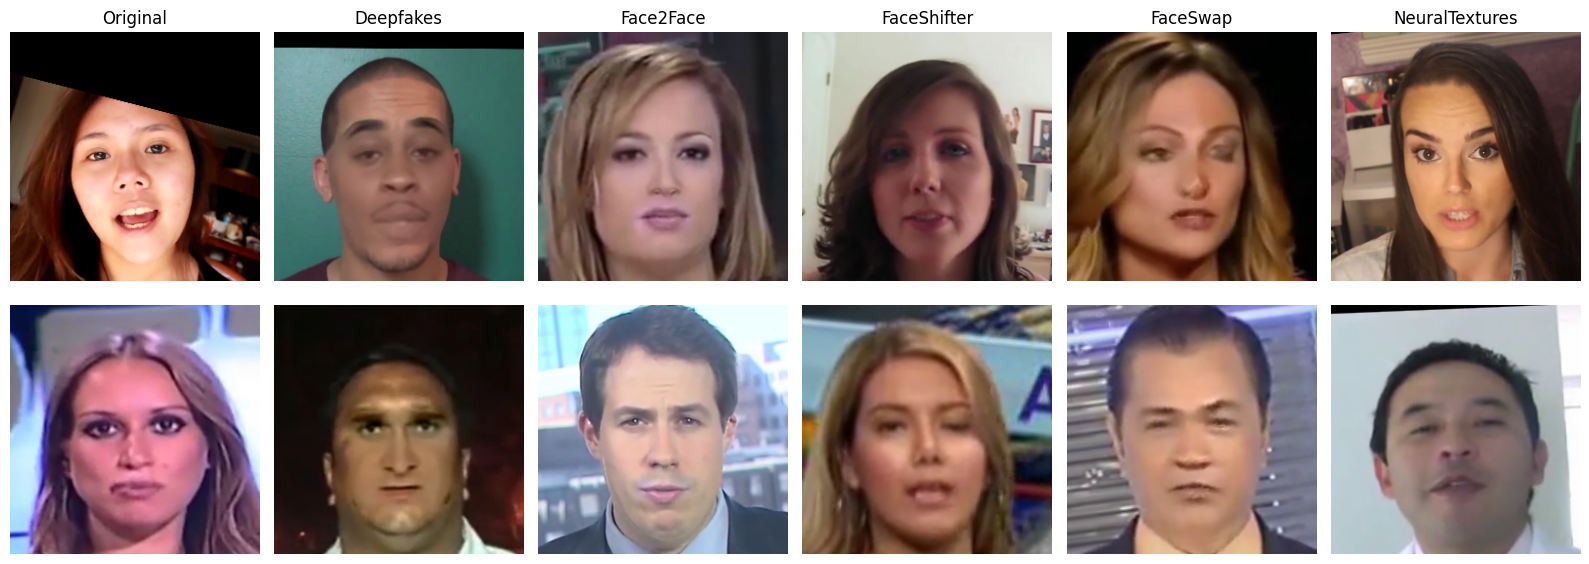

In [4]:

import matplotlib.pyplot as plt
from PIL import Image

categories = [
    "Original",
    "Deepfakes",
    "Face2Face",
    "FaceShifter",
    "FaceSwap",
    "NeuralTextures"
]

fig, axes = plt.subplots(
    2, 6,
    figsize=(16, 6)
)

for col, category in enumerate(categories):

    examples = manifest[
        manifest["method"] == category
    ].sample(
        n=2,
        random_state=SEED
    )

    for row, path in enumerate(examples["path"]):
        with Image.open(path) as im:
            axes[row, col].imshow(im.convert("RGB"))

        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(category)

plt.tight_layout()
plt.show()


In [5]:

# ============================================================
# ASSIGNMENT 3 - CROSS-DATASET EVALUATION SETUP
# ============================================================

from pathlib import Path
import shutil
import sys
import importlib

import torch
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SAVED_PROJECT = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-trained-models-results"
)

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")
OUTPUT_DIR = Path("/kaggle/working/assignment3")
MANIFEST = OUTPUT_DIR / "ffpp_evaluation_manifest.csv"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Restore code and checkpoints if needed
shutil.copytree(
    SAVED_PROJECT,
    PROJECT_DIR,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns("__pycache__", "*.tex")
)

sys.path.insert(0, str(PROJECT_DIR))
sys.path_importer_cache.pop(str(PROJECT_DIR), None)
importlib.invalidate_caches()

from config import MODEL_CONFIGS
from evaluate import load_trained_model

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", "Please enable Kaggle GPU."
assert MANIFEST.exists(), "FaceForensics++ manifest missing."

df = pd.read_csv(MANIFEST)

assert len(df) == 1600
assert (df["label"] == 0).sum() == 800
assert (df["label"] == 1).sum() == 800

# Same evaluation preprocessing as Assignment 2
eval_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor()
])

class FFPPDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["path"]) as im:
            image = im.convert("RGB")
            image = eval_transform(image)

        label = int(row["label"])

        return image, label

test_dataset = FFPPDataset(df)

MODELS = ["xception", "vgg16", "resnet50", "resnet101"]

print("GPU:", torch.cuda.get_device_name(0))
print("Evaluation images:", len(test_dataset))
print("Models:", MODELS)
print("All checkpoints restored.")


GPU: Tesla T4
Evaluation images: 1600
Models: ['xception', 'vgg16', 'resnet50', 'resnet101']
All checkpoints restored.


In [6]:

# ============================================================
# ASSIGNMENT 3 - FACEFORENSICS++ CLEAN EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix
)

all_results = []
all_predictions = []

for name in MODELS:

    print(f"\nEvaluating {name.upper()}...")

    model = load_trained_model(name, DEVICE)
    model.eval()

    batch_size = MODEL_CONFIGS[name]["batch_size"]

    loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    y_true = []
    y_pred = []
    y_prob = []

    for images, labels in loader:

        images = images.to(DEVICE)

        with torch.no_grad():
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)[:, 1]
            predictions = logits.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())
        y_prob.extend(probabilities.cpu().numpy().tolist())

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)

    # Complete evaluation metrics
    result = {
        "model": name,
        "dataset": "FaceForensics++",
        "n_samples": len(y_true),

        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),

        "real_recall": np.mean(
            y_pred[y_true == 0] == 0
        ),
        "fake_recall": np.mean(
            y_pred[y_true == 1] == 1
        ),

        "predicted_real": int(np.sum(y_pred == 0)),
        "predicted_fake": int(np.sum(y_pred == 1))
    }

    all_results.append(result)

    # Store sample-level predictions
    predictions_df = df[
        ["path", "label", "method", "video_id", "frame"]
    ].copy()

    predictions_df["model"] = name
    predictions_df["prediction"] = y_pred
    predictions_df["fake_probability"] = y_prob
    predictions_df["correct"] = (y_pred == y_true).astype(int)

    all_predictions.append(predictions_df)

    print(
        f"Accuracy: {result['accuracy']:.4f} | "
        f"F1: {result['f1']:.4f} | "
        f"AUC: {result['roc_auc']:.4f}"
    )

    del model

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# Save overall results
results_df = pd.DataFrame(all_results)

results_df.to_csv(
    OUTPUT_DIR / "ffpp_clean_results.csv",
    index=False
)

# Save all predictions
predictions_df = pd.concat(
    all_predictions, ignore_index=True
)

predictions_df.to_csv(
    OUTPUT_DIR / "ffpp_clean_predictions.csv",
    index=False
)

# Per-method results:
# For fake methods, correct detection = FAKE recall.
# For Original, correct detection = REAL recall.
method_results = (
    predictions_df
    .groupby(["model", "method"])
    .agg(
        n_images=("correct", "size"),
        correct_detection_rate=("correct", "mean"),
        mean_fake_probability=("fake_probability", "mean")
    )
    .reset_index()
)

method_results.to_csv(
    OUTPUT_DIR / "ffpp_method_results.csv",
    index=False
)

# Percentage summary
display(
    results_df[
        [
            "model", "accuracy", "precision",
            "recall", "f1", "roc_auc",
            "balanced_accuracy", "real_recall", "fake_recall"
        ]
    ].round(4)
)

print("\n=== METHOD-WISE DETECTION ===")

display(
    method_results.pivot(
        index="model",
        columns="method",
        values="correct_detection_rate"
    ).round(4)
)

print("\n=== SAVED FILES ===")

for filename in [
    "ffpp_clean_results.csv",
    "ffpp_clean_predictions.csv",
    "ffpp_method_results.csv"
]:
    print(OUTPUT_DIR / filename)

print("\nCross-dataset clean evaluation completed.")



Evaluating XCEPTION...


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Accuracy: 0.5406 | F1: 0.5864 | AUC: 0.5506

Evaluating VGG16...
Accuracy: 0.5019 | F1: 0.6675 | AUC: 0.5404

Evaluating RESNET50...
Accuracy: 0.4919 | F1: 0.6349 | AUC: 0.5056

Evaluating RESNET101...
Accuracy: 0.5106 | F1: 0.6410 | AUC: 0.4790


,model,accuracy,precision,recall,f1,roc_auc,balanced_accuracy,real_recall,fake_recall
0,xception,0.5406,0.5333,0.6512,0.5864,0.5506,0.5406,0.4300,0.6512
1,vgg16,0.5019,0.5009,1.0000,0.6675,0.5404,0.5019,0.0038,1.0000
2,resnet50,0.4919,0.4954,0.8838,0.6349,0.5056,0.4919,0.1000,0.8838
3,resnet101,0.5106,0.5062,0.8738,0.6410,0.4790,0.5106,0.1475,0.8738



=== METHOD-WISE DETECTION ===


method,Deepfakes,Face2Face,FaceShifter,FaceSwap,NeuralTextures,Original
model,,,,,,
resnet101,0.8500,0.8812,0.8500,0.9312,0.8562,0.1475
resnet50,0.9625,0.8875,0.8750,0.8688,0.8250,0.1000
vgg16,1.0000,1.0000,1.0000,1.0000,1.0000,0.0038
xception,0.7438,0.5938,0.7125,0.6438,0.5625,0.4300



=== SAVED FILES ===
/kaggle/working/assignment3/ffpp_clean_results.csv
/kaggle/working/assignment3/ffpp_clean_predictions.csv
/kaggle/working/assignment3/ffpp_method_results.csv

Cross-dataset clean evaluation completed.


In [7]:

# ============================================================
# ASSIGNMENT 3 - FACEFORENSICS++ FGSM EVALUATION
# Epsilon = 0.01, no retraining
# ============================================================

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from config import MODEL_CONFIGS
from evaluate import load_trained_model
from attacks.fgsm import fgsm_attack

EPSILON = 0.01

fgsm_results = []
fgsm_predictions = []

for name in MODELS:

    print(f"\nFGSM evaluation: {name.upper()}")

    model = load_trained_model(name, DEVICE)
    model.eval()

    loader = DataLoader(
        test_dataset,
        batch_size=MODEL_CONFIGS[name]["batch_size"],
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    true_labels = []
    clean_preds = []
    attacked_preds = []
    attacked_probs = []
    max_deltas = []

    for images, labels in loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Clean predictions
        with torch.no_grad():
            clean_logits = model(images)
            clean_pred = clean_logits.argmax(dim=1)

        # Generate adversarial examples
        adv_images = fgsm_attack(
            model,
            images,
            labels,
            epsilon=EPSILON
        )

        # Verify perturbation
        delta = (
            adv_images - images
        ).abs().flatten(1).max(dim=1).values

        max_deltas.extend(delta.cpu().tolist())

        # Adversarial predictions
        with torch.no_grad():
            adv_logits = model(adv_images)
            adv_prob = torch.softmax(
                adv_logits, dim=1
            )[:, 1]
            adv_pred = adv_logits.argmax(dim=1)

        true_labels.extend(labels.cpu().tolist())
        clean_preds.extend(clean_pred.cpu().tolist())
        attacked_preds.extend(adv_pred.cpu().tolist())
        attacked_probs.extend(adv_prob.cpu().tolist())

    y = np.asarray(true_labels)
    clean = np.asarray(clean_preds)
    adv = np.asarray(attacked_preds)
    probs = np.asarray(attacked_probs)

    result = {
        "model": name,
        "dataset": "FaceForensics++",
        "epsilon": EPSILON,
        "n_samples": len(y),

        "clean_accuracy": accuracy_score(y, clean),
        "fgsm_accuracy": accuracy_score(y, adv),

        "fgsm_balanced_accuracy":
            balanced_accuracy_score(y, adv),

        "fgsm_precision":
            precision_score(y, adv, zero_division=0),

        "fgsm_recall":
            recall_score(y, adv, zero_division=0),

        "fgsm_f1":
            f1_score(y, adv, zero_division=0),

        "fgsm_roc_auc":
            roc_auc_score(y, probs),

        "fgsm_real_recall":
            np.mean(adv[y == 0] == 0),

        "fgsm_fake_recall":
            np.mean(adv[y == 1] == 1),

        "predicted_real": int((adv == 0).sum()),
        "predicted_fake": int((adv == 1).sum()),

        "correct_to_wrong":
            int(((clean == y) & (adv != y)).sum()),

        "wrong_to_correct":
            int(((clean != y) & (adv == y)).sum()),

        "max_perturbation": max(max_deltas)
    }

    fgsm_results.append(result)

    per_image = df[
        ["path", "label", "method", "video_id", "frame"]
    ].copy()

    per_image["model"] = name
    per_image["clean_prediction"] = clean
    per_image["fgsm_prediction"] = adv
    per_image["fgsm_fake_probability"] = probs
    per_image["fgsm_correct"] = (adv == y).astype(int)

    fgsm_predictions.append(per_image)

    print(
        f"Clean: {result['clean_accuracy']:.4f} | "
        f"FGSM: {result['fgsm_accuracy']:.4f} | "
        f"Balanced: {result['fgsm_balanced_accuracy']:.4f}"
    )

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# Save overall FGSM results
fgsm_df = pd.DataFrame(fgsm_results)

fgsm_df.to_csv(
    OUTPUT_DIR / "ffpp_fgsm_results.csv",
    index=False
)

# Save predictions
fgsm_pred_df = pd.concat(
    fgsm_predictions,
    ignore_index=True
)

fgsm_pred_df.to_csv(
    OUTPUT_DIR / "ffpp_fgsm_predictions.csv",
    index=False
)

# Method-wise results
fgsm_method_df = (
    fgsm_pred_df
    .groupby(["model", "method"])
    .agg(
        n_images=("fgsm_correct", "size"),
        correct_detection_rate=("fgsm_correct", "mean")
    )
    .reset_index()
)

fgsm_method_df.to_csv(
    OUTPUT_DIR / "ffpp_fgsm_method_results.csv",
    index=False
)

# Safety checks
assert len(fgsm_df) == 4
assert (fgsm_df["n_samples"] == 1600).all()
assert (
    fgsm_df["max_perturbation"] <= EPSILON + 1e-6
).all()

print("\n=== FGSM OVERALL RESULTS ===")
display(fgsm_df.round(4))

print("\n=== FGSM METHOD-WISE RESULTS ===")
display(
    fgsm_method_df.pivot(
        index="model",
        columns="method",
        values="correct_detection_rate"
    ).round(4)
)

print("\nSaved results in:", OUTPUT_DIR)



FGSM evaluation: XCEPTION


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Clean: 0.5406 | FGSM: 0.0712 | Balanced: 0.0712

FGSM evaluation: VGG16
Clean: 0.5019 | FGSM: 0.1544 | Balanced: 0.1544

FGSM evaluation: RESNET50
Clean: 0.4919 | FGSM: 0.4813 | Balanced: 0.4813

FGSM evaluation: RESNET101
Clean: 0.5106 | FGSM: 0.3519 | Balanced: 0.3519

=== FGSM OVERALL RESULTS ===


,model,dataset,epsilon,n_samples,clean_accuracy,fgsm_accuracy,fgsm_balanced_accuracy,fgsm_precision,fgsm_recall,fgsm_f1,fgsm_roc_auc,fgsm_real_recall,fgsm_fake_recall,predicted_real,predicted_fake,correct_to_wrong,wrong_to_correct,max_perturbation
0,xception,FaceForensics++,0.01,1600,0.5406,0.0712,0.0712,0.1247,0.1425,0.1330,0.0002,0.0000,0.1425,686,914,766,15,0.01
1,vgg16,FaceForensics++,0.01,1600,0.5019,0.1544,0.1544,0.2359,0.3088,0.2675,0.0000,0.0000,0.3088,553,1047,556,0,0.01
2,resnet50,FaceForensics++,0.01,1600,0.4919,0.4812,0.4812,0.4904,0.9625,0.6498,0.0824,0.0000,0.9625,30,1570,90,73,0.01
3,resnet101,FaceForensics++,0.01,1600,0.5106,0.3519,0.3519,0.4128,0.7012,0.5197,0.0261,0.0025,0.7012,241,1359,294,40,0.01



=== FGSM METHOD-WISE RESULTS ===


method,Deepfakes,Face2Face,FaceShifter,FaceSwap,NeuralTextures,Original
model,,,,,,
resnet101,0.6750,0.7062,0.7375,0.7938,0.5938,0.0025
resnet50,1.0000,0.9375,0.9688,0.9688,0.9375,0.0000
vgg16,0.3562,0.3250,0.3562,0.2688,0.2375,0.0000
xception,0.2188,0.0438,0.1625,0.1688,0.1188,0.0000



Saved results in: /kaggle/working/assignment3


In [12]:

# ============================================================
# ASSIGNMENT 3 - JPEG PREPROCESSING DEFENSE
# No retraining | FGSM epsilon = 0.01
# JPEG Quality = 75
# ============================================================

import io
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torchvision.transforms.functional import (
    to_pil_image, to_tensor
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score
)

EPSILON = 0.01
JPEG_QUALITY = 75

# ------------------------------------------------------------
# JPEG compression in [0,1] image space
# ------------------------------------------------------------

def jpeg_compress_batch(images, quality=75):
    compressed = []

    for image in images.detach().cpu():
        pil_image = to_pil_image(image)

        buffer = io.BytesIO()

        pil_image.save(
            buffer,
            format="JPEG",
            quality=quality
        )

        buffer.seek(0)

        with Image.open(buffer) as decoded:
            result = decoded.convert("RGB")
            compressed.append(to_tensor(result))

        buffer.close()

    return torch.stack(compressed).to(images.device)


def evaluate_condition(y, pred, prob):
    y = np.asarray(y)
    pred = np.asarray(pred)
    prob = np.asarray(prob)

    return {
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, prob),
        "real_recall": np.mean(pred[y == 0] == 0),
        "fake_recall": np.mean(pred[y == 1] == 1),
        "predicted_real": int((pred == 0).sum()),
        "predicted_fake": int((pred == 1).sum())
    }


all_results = []
all_predictions = []

for name in MODELS:

    print(f"\nEvaluating JPEG defense: {name.upper()}")

    model = load_trained_model(name, DEVICE)
    model.eval()

    batch_size = MODEL_CONFIGS[name]["batch_size"]

    loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    y_all = []

    conditions = [
        "clean",
        "jpeg_clean",
        "fgsm",
        "jpeg_fgsm"
    ]

    predictions = {c: [] for c in conditions}
    probabilities = {c: [] for c in conditions}

    for images, labels in loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Generate FGSM attack against original model
        adv_images = fgsm_attack(
            model,
            images,
            labels,
            epsilon=EPSILON
        )

        # JPEG preprocessing
        jpeg_clean = jpeg_compress_batch(
            images, quality=JPEG_QUALITY
        )

        jpeg_adv = jpeg_compress_batch(
            adv_images, quality=JPEG_QUALITY
        )

        batch_conditions = {
            "clean": images,
            "jpeg_clean": jpeg_clean,
            "fgsm": adv_images,
            "jpeg_fgsm": jpeg_adv
        }

        with torch.no_grad():
            for condition, batch in batch_conditions.items():

                logits = model(batch)
                probs = torch.softmax(logits, dim=1)[:, 1]
                preds = logits.argmax(dim=1)

                predictions[condition].extend(
                    preds.cpu().numpy().tolist()
                )

                probabilities[condition].extend(
                    probs.cpu().numpy().tolist()
                )

        y_all.extend(labels.cpu().numpy().tolist())

    y_all = np.asarray(y_all)

    # Calculate metrics for each condition
    for condition in conditions:

        pred = np.asarray(predictions[condition])
        prob = np.asarray(probabilities[condition])

        metrics = evaluate_condition(y_all, pred, prob)

        all_results.append({
            "model": name,
            "condition": condition,
            "epsilon": EPSILON,
            "jpeg_quality": JPEG_QUALITY,
            "n_samples": len(y_all),
            **metrics
        })

        sample_df = df[
            ["path", "label", "method", "video_id", "frame"]
        ].copy()

        sample_df["model"] = name
        sample_df["condition"] = condition
        sample_df["prediction"] = pred
        sample_df["fake_probability"] = prob
        sample_df["correct"] = (pred == y_all).astype(int)

        all_predictions.append(sample_df)

    del model

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    print(f"Completed {name}")

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

jpeg_results = pd.DataFrame(all_results)

jpeg_results.to_csv(
    OUTPUT / "ffpp_jpeg_defense_results.csv",
    index=False
)

jpeg_predictions = pd.concat(
    all_predictions,
    ignore_index=True
)

jpeg_predictions.to_csv(
    OUTPUT / "ffpp_jpeg_defense_predictions.csv",
    index=False
)

# Method-level results
jpeg_methods = (
    jpeg_predictions
    .groupby(["model", "condition", "method"])
    .agg(
        n_images=("correct", "size"),
        correct_detection_rate=("correct", "mean")
    )
    .reset_index()
)

jpeg_methods.to_csv(
    OUTPUT / "ffpp_jpeg_defense_method_results.csv",
    index=False
)

print("\n=== ACCURACY COMPARISON ===")

display(
    jpeg_results.pivot(
        index="model",
        columns="condition",
        values="accuracy"
    ).round(4)
)

print("\n=== BALANCED ACCURACY ===")

display(
    jpeg_results.pivot(
        index="model",
        columns="condition",
        values="balanced_accuracy"
    ).round(4)
)

print("\n=== CLASS-WISE RECALL ===")

display(
    jpeg_results[
        [
            "model", "condition",
            "real_recall", "fake_recall",
            "predicted_real", "predicted_fake"
        ]
    ].round(4)
)

print("\nSaved JPEG defense results:", OUTPUT)



Evaluating JPEG defense: XCEPTION


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Completed xception

Evaluating JPEG defense: VGG16
Completed vgg16

Evaluating JPEG defense: RESNET50
Completed resnet50

Evaluating JPEG defense: RESNET101
Completed resnet101

=== ACCURACY COMPARISON ===


condition,clean,fgsm,jpeg_clean,jpeg_fgsm
model,,,,
resnet101,0.5106,0.3519,0.5150,0.2588
resnet50,0.4919,0.4812,0.4988,0.3438
vgg16,0.5019,0.1544,0.5019,0.3556
xception,0.5406,0.0712,0.5306,0.0213



=== BALANCED ACCURACY ===


condition,clean,fgsm,jpeg_clean,jpeg_fgsm
model,,,,
resnet101,0.5106,0.3519,0.5150,0.2588
resnet50,0.4919,0.4812,0.4988,0.3438
vgg16,0.5019,0.1544,0.5019,0.3556
xception,0.5406,0.0712,0.5306,0.0213



=== CLASS-WISE RECALL ===


,model,condition,real_recall,fake_recall,predicted_real,predicted_fake
0,xception,clean,0.4300,0.6512,623,977
1,xception,jpeg_clean,0.3900,0.6712,575,1025
2,xception,fgsm,0.0000,0.1425,686,914
3,xception,jpeg_fgsm,0.0000,0.0425,766,834
4,vgg16,clean,0.0038,1.0000,3,1597
5,vgg16,jpeg_clean,0.0038,1.0000,3,1597
6,vgg16,fgsm,0.0000,0.3088,553,1047
7,vgg16,jpeg_fgsm,0.0000,0.7113,231,1369
8,resnet50,clean,0.1000,0.8838,173,1427
9,resnet50,jpeg_clean,0.0838,0.9138,136,1464



Saved JPEG defense results: /kaggle/working/assignment3


In [13]:

from pathlib import Path
import shutil
import subprocess
import json

DATASET_ID = "haiderrasoolqadri/dfdc-ffpp-assignment3-results"

SOURCE = Path("/kaggle/working/assignment3")
EXPORT = Path("/kaggle/working/assignment3_backup")

# Existing dataset, if already mounted
EXISTING = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-ffpp-assignment3-results"
)

if not SOURCE.exists():
    raise FileNotFoundError("Assignment 3 results folder not found.")

# Prepare fresh backup
if EXPORT.exists():
    shutil.rmtree(EXPORT)

EXPORT.mkdir(parents=True)

# Preserve previous dataset files
if EXISTING.exists():
    shutil.copytree(EXISTING, EXPORT, dirs_exist_ok=True)

# Add latest results (including JPEG defense)
shutil.copytree(SOURCE, EXPORT, dirs_exist_ok=True)

# Dataset metadata
metadata = {
    "title": "DFDC FFPP Assignment 3 Results",
    "id": DATASET_ID,
    "licenses": [{"name": "unknown"}]
}

(EXPORT / "dataset-metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

required = [
    "ffpp_evaluation_manifest.csv",
    "ffpp_clean_results.csv",
    "ffpp_fgsm_results.csv",
    "ffpp_jpeg_defense_results.csv",
    "ffpp_jpeg_defense_predictions.csv",
    "ffpp_jpeg_defense_method_results.csv",
]

for name in required:
    assert (EXPORT / name).exists(), f"Missing: {name}"

print("Files ready for upload:")
for p in sorted(EXPORT.iterdir()):
    print(" -", p.name)

# Create first version or update existing dataset
cmd = [
    "kaggle", "datasets",
    "version" if EXISTING.exists() else "create",
    "-p", str(EXPORT),
    "--dir-mode", "zip"
]

if EXISTING.exists():
    cmd.extend([
        "-m", "Added JPEG defense experiments and latest Assignment 3 results"
    ])

print("\nUploading dataset...")
result = subprocess.run(cmd, text=True, capture_output=True)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Dataset upload failed.")

print("\nDataset upload succeeded!")
print("https://www.kaggle.com/datasets/" + DATASET_ID)


Files ready for upload:
 - dataset-metadata.json
 - ffpp_clean_predictions.csv
 - ffpp_clean_results.csv
 - ffpp_evaluation_manifest.csv
 - ffpp_fgsm_method_results.csv
 - ffpp_fgsm_predictions.csv
 - ffpp_fgsm_results.csv
 - ffpp_jpeg_defense_method_results.csv
 - ffpp_jpeg_defense_predictions.csv
 - ffpp_jpeg_defense_results.csv
 - ffpp_method_results.csv

Uploading dataset...
Starting upload for file ffpp_evaluation_manifest.csv
Upload successful: ffpp_evaluation_manifest.csv (190KB)
Starting upload for file ffpp_fgsm_predictions.csv
Upload successful: ffpp_fgsm_predictions.csv (927KB)
Starting upload for file ffpp_jpeg_defense_method_results.csv
Upload successful: ffpp_jpeg_defense_method_results.csv (4KB)
Starting upload for file ffpp_fgsm_method_results.csv
Upload successful: ffpp_fgsm_method_results.csv (771B)
Starting upload for file ffpp_clean_predictions.csv
Upload successful: ffpp_clean_predictions.csv (927KB)
Starting upload for file ffpp_fgsm_results.csv
Upload successful:

In [1]:

from pathlib import Path
import shutil
import sys
import importlib

import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

BASE = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-trained-models-results"
)

BACKUP = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-ffpp-assignment3-results"
)

PROJECT = Path("/kaggle/working/dfdc_reproduction")
OUTPUT = Path("/kaggle/working/assignment3")

OUTPUT.mkdir(parents=True, exist_ok=True)

if not (PROJECT / "config.py").exists():
    shutil.copytree(BASE, PROJECT, dirs_exist_ok=True)

sys.path.insert(0, str(PROJECT))
sys.path_importer_cache.pop(str(PROJECT), None)
importlib.invalidate_caches()

from config import MODEL_CONFIGS
from evaluate import load_trained_model
from attacks.fgsm import fgsm_attack

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", "Enable Kaggle GPU."

MANIFEST = OUTPUT / "ffpp_evaluation_manifest.csv"

if not MANIFEST.exists():
    source = BACKUP / "ffpp_evaluation_manifest.csv"
    if not source.exists():
        raise FileNotFoundError("Saved FF++ manifest missing.")
    shutil.copy2(source, MANIFEST)

df = pd.read_csv(MANIFEST)

eval_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor()
])

class FFPPDataset(Dataset):
    def __init__(self, table):
        self.table = table.reset_index(drop=True)

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        with Image.open(row["path"]) as img:
            image = eval_transform(img.convert("RGB"))
        return image, int(row["label"])

test_dataset = FFPPDataset(df)

MODELS = ["xception", "vgg16", "resnet50", "resnet101"]

assert len(df) == 1600
assert (df["label"] == 0).sum() == 800
assert (df["label"] == 1).sum() == 800

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", len(test_dataset), "images")
print("Existing checkpoints ready.")


GPU: Tesla T4
Dataset: 1600 images
Existing checkpoints ready.


In [2]:

# ============================================================
# ASSIGNMENT 3: GAUSSIAN SMOOTHING DEFENSE
# Kernel = 3x3, Sigma = 0.5
# ============================================================

import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score
)

EPSILON = 0.01
SIGMA = 0.5
KERNEL_SIZE = 3

def gaussian_smoothing(images):
    return TF.gaussian_blur(
        images,
        kernel_size=[KERNEL_SIZE, KERNEL_SIZE],
        sigma=[SIGMA, SIGMA]
    )

def calc_metrics(y, pred, prob):
    return {
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, prob),
        "real_recall": np.mean(pred[y == 0] == 0),
        "fake_recall": np.mean(pred[y == 1] == 1),
        "predicted_real": int((pred == 0).sum()),
        "predicted_fake": int((pred == 1).sum())
    }

results = []
predictions = []

for name in MODELS:

    print(f"\nGaussian experiment: {name.upper()}")

    model = load_trained_model(name, DEVICE)
    model.eval()

    loader = DataLoader(
        test_dataset,
        batch_size=MODEL_CONFIGS[name]["batch_size"],
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    y_all = []
    store = {
        c: {"pred": [], "prob": []}
        for c in [
            "clean",
            "gaussian_clean",
            "fgsm",
            "gaussian_fgsm"
        ]
    }

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Attack original model
        adv_images = fgsm_attack(
            model, images, labels, epsilon=EPSILON
        )

        variants = {
            "clean": images,
            "gaussian_clean": gaussian_smoothing(images),
            "fgsm": adv_images,
            "gaussian_fgsm": gaussian_smoothing(adv_images)
        }

        with torch.no_grad():
            for condition, batch in variants.items():
                logits = model(batch)
                prob = torch.softmax(logits, dim=1)[:, 1]
                pred = logits.argmax(dim=1)

                store[condition]["pred"].extend(
                    pred.cpu().tolist()
                )
                store[condition]["prob"].extend(
                    prob.cpu().tolist()
                )

        y_all.extend(labels.cpu().tolist())

    y = np.asarray(y_all)

    for condition, data in store.items():
        pred = np.asarray(data["pred"])
        prob = np.asarray(data["prob"])

        results.append({
            "model": name,
            "condition": condition,
            "sigma": SIGMA,
            "kernel_size": KERNEL_SIZE,
            "epsilon": EPSILON,
            **calc_metrics(y, pred, prob)
        })

        rows = df[
            ["path", "label", "method", "video_id", "frame"]
        ].copy()
        rows["model"] = name
        rows["condition"] = condition
        rows["prediction"] = pred
        rows["fake_probability"] = prob
        rows["correct"] = (pred == y).astype(int)
        predictions.append(rows)

    print("Completed", name)

    del model
    torch.cuda.empty_cache()

gaussian_results = pd.DataFrame(results)
gaussian_predictions = pd.concat(
    predictions, ignore_index=True
)

gaussian_results.to_csv(
    OUTPUT / "ffpp_gaussian_results.csv",
    index=False
)

gaussian_predictions.to_csv(
    OUTPUT / "ffpp_gaussian_predictions.csv",
    index=False
)

print("\n=== ACCURACY ===")
display(
    gaussian_results.pivot(
        index="model",
        columns="condition",
        values="accuracy"
    ).round(4)
)

print("\n=== CLASS-WISE RECALL ===")
display(
    gaussian_results[
        ["model", "condition", "real_recall", "fake_recall"]
    ].round(4)
)

print("\nResults saved:", OUTPUT)



Gaussian experiment: XCEPTION


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Completed xception

Gaussian experiment: VGG16
Completed vgg16

Gaussian experiment: RESNET50
Completed resnet50

Gaussian experiment: RESNET101
Completed resnet101

=== ACCURACY ===


condition,clean,fgsm,gaussian_clean,gaussian_fgsm
model,,,,
resnet101,0.5106,0.3519,0.5000,0.2450
resnet50,0.4919,0.4812,0.4950,0.4038
vgg16,0.5019,0.1544,0.5019,0.1531
xception,0.5406,0.0712,0.5481,0.0238



=== CLASS-WISE RECALL ===


,model,condition,real_recall,fake_recall
0,xception,clean,0.4300,0.6512
1,xception,gaussian_clean,0.5062,0.5900
2,xception,fgsm,0.0000,0.1425
3,xception,gaussian_fgsm,0.0000,0.0475
4,vgg16,clean,0.0038,1.0000
5,vgg16,gaussian_clean,0.0038,1.0000
6,vgg16,fgsm,0.0000,0.3088
7,vgg16,gaussian_fgsm,0.0000,0.3062
8,resnet50,clean,0.1000,0.8838
9,resnet50,gaussian_clean,0.1188,0.8712



Results saved: /kaggle/working/assignment3


In [3]:

from pathlib import Path

OUTPUT = Path("/kaggle/working/assignment3")

required = [
    "ffpp_evaluation_manifest.csv",
    "ffpp_clean_results.csv",
    "ffpp_fgsm_results.csv",
    "ffpp_jpeg_defense_results.csv",
    "ffpp_gaussian_results.csv",
]

for filename in required:
    path = OUTPUT / filename
    print(
        "FOUND" if path.exists() else "MISSING",
        filename
    )

print("\nReady for adaptive-head dataset preparation.")


FOUND ffpp_evaluation_manifest.csv
MISSING ffpp_clean_results.csv
MISSING ffpp_fgsm_results.csv
MISSING ffpp_jpeg_defense_results.csv
FOUND ffpp_gaussian_results.csv

Ready for adaptive-head dataset preparation.


In [4]:

from pathlib import Path
import shutil

OUTPUT = Path("/kaggle/working/assignment3")
OUTPUT.mkdir(parents=True, exist_ok=True)

BACKUP = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-ffpp-assignment3-results"
)

REQUIRED = [
    "ffpp_evaluation_manifest.csv",
    "ffpp_clean_results.csv",
    "ffpp_clean_predictions.csv",
    "ffpp_method_results.csv",
    "ffpp_fgsm_results.csv",
    "ffpp_fgsm_predictions.csv",
    "ffpp_fgsm_method_results.csv",
    "ffpp_jpeg_defense_results.csv",
    "ffpp_jpeg_defense_predictions.csv",
    "ffpp_jpeg_defense_method_results.csv",
    "ffpp_gaussian_results.csv",
    "ffpp_gaussian_predictions.csv",
]

print("Backup dataset available:", BACKUP.exists())

for filename in REQUIRED:
    target = OUTPUT / filename

    if target.exists():
        print("ALREADY PRESENT:", filename)
        continue

    source = BACKUP / filename

    if source.is_file():
        shutil.copy2(source, target)
        print("RESTORED:", filename)
    else:
        print("NOT IN BACKUP:", filename)

print("\n=== FINAL STATUS ===")

missing = []

for filename in REQUIRED:
    if not (OUTPUT / filename).is_file():
        missing.append(filename)

print("Available:", len(REQUIRED) - len(missing))
print("Missing:", len(missing))

if missing:
    print("\nMissing files:")
    for filename in missing:
        print(" -", filename)
else:
    print("\nAll files restored successfully.")


Backup dataset available: True
ALREADY PRESENT: ffpp_evaluation_manifest.csv
RESTORED: ffpp_clean_results.csv
RESTORED: ffpp_clean_predictions.csv
RESTORED: ffpp_method_results.csv
RESTORED: ffpp_fgsm_results.csv
RESTORED: ffpp_fgsm_predictions.csv
RESTORED: ffpp_fgsm_method_results.csv
RESTORED: ffpp_jpeg_defense_results.csv
RESTORED: ffpp_jpeg_defense_predictions.csv
RESTORED: ffpp_jpeg_defense_method_results.csv
ALREADY PRESENT: ffpp_gaussian_results.csv
ALREADY PRESENT: ffpp_gaussian_predictions.csv

=== FINAL STATUS ===
Available: 12
Missing: 0

All files restored successfully.


In [5]:

import pandas as pd

OUTPUT = Path("/kaggle/working/assignment3")

files = {
    "Clean": "ffpp_clean_results.csv",
    "FGSM": "ffpp_fgsm_results.csv",
    "JPEG": "ffpp_jpeg_defense_results.csv",
    "Gaussian": "ffpp_gaussian_results.csv",
}

for experiment, filename in files.items():

    path = OUTPUT / filename

    print(f"\n=== {experiment.upper()} ===")

    if path.exists():
        data = pd.read_csv(path)
        print("Rows:", len(data))
        display(data.head())
    else:
        print("MISSING:", filename)



=== CLEAN ===
Rows: 4


,model,dataset,n_samples,accuracy,precision,recall,f1,roc_auc,balanced_accuracy,real_recall,fake_recall,predicted_real,predicted_fake
0,xception,FaceForensics++,1600,0.540625,0.533265,0.65125,0.586382,0.550609,0.540625,0.43000,0.65125,623,977
1,vgg16,FaceForensics++,1600,0.501875,0.500939,1.00000,0.667501,0.540440,0.501875,0.00375,1.00000,3,1597
2,resnet50,FaceForensics++,1600,0.491875,0.495445,0.88375,0.634935,0.505563,0.491875,0.10000,0.88375,173,1427
3,resnet101,FaceForensics++,1600,0.510625,0.506155,0.87375,0.640990,0.478970,0.510625,0.14750,0.87375,219,1381



=== FGSM ===
Rows: 4


,model,dataset,epsilon,n_samples,clean_accuracy,fgsm_accuracy,fgsm_balanced_accuracy,fgsm_precision,fgsm_recall,fgsm_f1,fgsm_roc_auc,fgsm_real_recall,fgsm_fake_recall,predicted_real,predicted_fake,correct_to_wrong,wrong_to_correct,max_perturbation
0,xception,FaceForensics++,0.01,1600,0.540625,0.071250,0.071250,0.124726,0.14250,0.133022,0.000158,0.0000,0.14250,686,914,766,15,0.01
1,vgg16,FaceForensics++,0.01,1600,0.501875,0.154375,0.154375,0.235912,0.30875,0.267461,0.000000,0.0000,0.30875,553,1047,556,0,0.01
2,resnet50,FaceForensics++,0.01,1600,0.491875,0.481250,0.481250,0.490446,0.96250,0.649789,0.082420,0.0000,0.96250,30,1570,90,73,0.01
3,resnet101,FaceForensics++,0.01,1600,0.510625,0.351875,0.351875,0.412804,0.70125,0.519685,0.026106,0.0025,0.70125,241,1359,294,40,0.01



=== JPEG ===
Rows: 16


,model,condition,epsilon,jpeg_quality,n_samples,accuracy,balanced_accuracy,f1,roc_auc,real_recall,fake_recall,predicted_real,predicted_fake
0,xception,clean,0.01,75,1600,0.540625,0.540625,0.586382,0.550609,0.43000,0.65125,623,977
1,xception,jpeg_clean,0.01,75,1600,0.530625,0.530625,0.588493,0.537238,0.39000,0.67125,575,1025
2,xception,fgsm,0.01,75,1600,0.071250,0.071250,0.133022,0.000158,0.00000,0.14250,686,914
3,xception,jpeg_fgsm,0.01,75,1600,0.021250,0.021250,0.041616,0.000119,0.00000,0.04250,766,834
4,vgg16,clean,0.01,75,1600,0.501875,0.501875,0.667501,0.540440,0.00375,1.00000,3,1597



=== GAUSSIAN ===
Rows: 16


,model,condition,sigma,kernel_size,epsilon,accuracy,balanced_accuracy,f1,roc_auc,real_recall,fake_recall,predicted_real,predicted_fake
0,xception,clean,0.5,3,0.01,0.540625,0.540625,0.586382,0.550609,0.43000,0.65125,623,977
1,xception,gaussian_clean,0.5,3,0.01,0.548125,0.548125,0.566287,0.556532,0.50625,0.59000,733,867
2,xception,fgsm,0.5,3,0.01,0.071250,0.071250,0.133022,0.000158,0.00000,0.14250,686,914
3,xception,gaussian_fgsm,0.5,3,0.01,0.023750,0.023750,0.046398,0.000006,0.00000,0.04750,762,838
4,vgg16,clean,0.5,3,0.01,0.501875,0.501875,0.667501,0.540440,0.00375,1.00000,3,1597


In [6]:

# ============================================================
# ASSIGNMENT 3 - ADAPTIVE HEAD DATA PREPARATION
# Source-disjoint train / validation / held-out test
# ============================================================

from pathlib import Path
import random
import pandas as pd

SEED = 42
rng = random.Random(SEED)

ROOT = Path(
    "/kaggle/input/datasets/adham7elmy/"
    "faceforencispp-extracted-frames"
)

OUTPUT = Path("/kaggle/working/assignment3")
OUTPUT.mkdir(parents=True, exist_ok=True)

METHODS = [
    "Deepfakes",
    "Face2Face",
    "FaceShifter",
    "FaceSwap",
    "NeuralTextures"
]

EXT = {".png", ".jpg", ".jpeg", ".webp"}

# Existing final evaluation data
test = pd.read_csv(
    OUTPUT / "ffpp_evaluation_manifest.csv"
)

assert len(test) == 1600

def source_ids(video_name):
    return set(str(video_name).split("_"))

def get_frames(folder):
    return sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in EXT
    )

def sample_frames(folder, n=4):
    frames = get_frames(folder)

    if len(frames) < n:
        return []

    indices = [
        round(i * (len(frames) - 1) / (n - 1))
        for i in range(n)
    ]
    return [frames[i] for i in indices]

# Block all source IDs appearing in existing test set.
blocked = set()

for video_id in test["video_id"].unique():
    blocked.update(source_ids(video_id))

print("Blocked test source IDs:", len(blocked))

real_folders = sorted(
    p for p in (ROOT / "real").iterdir()
    if p.is_dir() and len(get_frames(p)) >= 4
)

fake_folders = {}

for method in METHODS:
    fake_folders[method] = sorted(
        p for p in (ROOT / "fake" / method).iterdir()
        if p.is_dir() and len(get_frames(p)) >= 4
    )

# Reserve source IDs globally to prevent overlap
# between training, validation and testing.
used_sources = set(blocked)

def create_split(split_name, n_real, n_fake_per_method):
    records = []

    # Select REAL videos with unused source IDs
    real_candidates = [
        p for p in real_folders
        if not (source_ids(p.name) & used_sources)
    ]

    rng.shuffle(real_candidates)

    selected_real = real_candidates[:n_real]

    if len(selected_real) != n_real:
        raise RuntimeError(
            f"Not enough REAL videos for {split_name}"
        )

    for folder in selected_real:
        used_sources.update(source_ids(folder.name))

        for frame in sample_frames(folder):
            records.append({
                "path": str(frame),
                "label": 0,
                "method": "Original",
                "video_id": folder.name,
                "split": split_name
            })

    # Select fake videos from each manipulation method
    for method in METHODS:
        candidates = list(fake_folders[method])
        rng.shuffle(candidates)

        selected = []

        for folder in candidates:
            ids = source_ids(folder.name)

            if ids & used_sources:
                continue

            selected.append(folder)
            used_sources.update(ids)

            if len(selected) == n_fake_per_method:
                break

        if len(selected) != n_fake_per_method:
            raise RuntimeError(
                f"Not enough {method} videos for {split_name}"
            )

        for folder in selected:
            for frame in sample_frames(folder):
                records.append({
                    "path": str(frame),
                    "label": 1,
                    "method": method,
                    "video_id": folder.name,
                    "split": split_name
                })

    result = pd.DataFrame(records)
    return result.sample(
        frac=1,
        random_state=SEED
    ).reset_index(drop=True)

# Training:
# 60 REAL + 12 videos from each of 5 fake methods
train_manifest = create_split(
    "train", n_real=60, n_fake_per_method=12
)

# Validation:
# 20 REAL + 4 videos from each of 5 fake methods
val_manifest = create_split(
    "validation", n_real=20, n_fake_per_method=4
)

train_manifest.to_csv(
    OUTPUT / "head_train_manifest.csv",
    index=False
)

val_manifest.to_csv(
    OUTPUT / "head_val_manifest.csv",
    index=False
)

# ============================================================
# VALIDATION CHECKS
# ============================================================

def all_source_ids(table):
    ids = set()
    for vid in table["video_id"].unique():
        ids.update(source_ids(vid))
    return ids

train_ids = all_source_ids(train_manifest)
val_ids = all_source_ids(val_manifest)
test_ids = all_source_ids(test)

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(train_manifest) == 480
assert len(val_manifest) == 160

assert (train_manifest["label"] == 0).sum() == 240
assert (train_manifest["label"] == 1).sum() == 240

assert (val_manifest["label"] == 0).sum() == 80
assert (val_manifest["label"] == 1).sum() == 80

print("\n=== HEAD DATASET READY ===")

print("Training images:", len(train_manifest))
print("Validation images:", len(val_manifest))
print("Final test images:", len(test))

print("\nTrain distribution:")
print(train_manifest.groupby("method").size())

print("\nValidation distribution:")
print(val_manifest.groupby("method").size())

print("\nSource overlap checks passed.")

print("\nFiles saved:")
print(OUTPUT / "head_train_manifest.csv")
print(OUTPUT / "head_val_manifest.csv")


Blocked test source IDs: 290

=== HEAD DATASET READY ===
Training images: 480
Validation images: 160
Final test images: 1600

Train distribution:
method
Deepfakes          48
Face2Face          48
FaceShifter        48
FaceSwap           48
NeuralTextures     48
Original          240
dtype: int64

Validation distribution:
method
Deepfakes         16
Face2Face         16
FaceShifter       16
FaceSwap          16
NeuralTextures    16
Original          80
dtype: int64

Source overlap checks passed.

Files saved:
/kaggle/working/assignment3/head_train_manifest.csv
/kaggle/working/assignment3/head_val_manifest.csv


In [7]:

# ====================================================
# ASSIGNMENT 3 - STEP 7
# Lightweight Clean / Attacked Detection Head
# ====================================================

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import joblib

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    classification_report, confusion_matrix, roc_auc_score
)

PROJECT = Path("/kaggle/working/dfdc_reproduction")
OUTPUT = Path("/kaggle/working/assignment3")
sys.path.insert(0, str(PROJECT))

from evaluate import load_trained_model
from attacks.fgsm import fgsm_attack

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", "Enable Kaggle GPU."

EPSILON = 0.01
BATCH_SIZE = 16

transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor()
])

class HeadDataset(Dataset):
    def __init__(self, manifest_path):
        self.df = pd.read_csv(manifest_path)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(row["path"]) as img:
            image = transform(img.convert("RGB"))
        return image, int(row["label"])


# Image-only statistical features.
# No access to the clean reference or ground-truth
# label is needed during detection.
def extract_features(images):

    x = images.detach().float()

    smooth = F.avg_pool2d(
        x, kernel_size=3, stride=1, padding=1
    )
    residual = x - smooth

    dx = x[:, :, :, 1:] - x[:, :, :, :-1]
    dy = x[:, :, 1:, :] - x[:, :, :-1, :]

    features = []

    for tensor in [x, residual]:
        features.extend([
            tensor.mean(dim=(2, 3)),
            tensor.std(dim=(2, 3)),
            tensor.abs().mean(dim=(2, 3))
        ])

    features.extend([
        dx.abs().mean(dim=(2, 3)),
        dx.std(dim=(2, 3)),
        dy.abs().mean(dim=(2, 3)),
        dy.std(dim=(2, 3))
    ])

    return torch.cat(
        features, dim=1
    ).cpu().numpy()


def generate_head_features(manifest_path, split):

    dataset = HeadDataset(manifest_path)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    rows = []

    for batch_idx, (images, labels) in enumerate(loader):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Generate FGSM using frozen Xception model
        attacked = fgsm_attack(
            source_model,
            images,
            labels,
            epsilon=EPSILON
        ).detach()

        clean_features = extract_features(images)
        attack_features = extract_features(attacked)

        for i in range(len(labels)):

            image_idx = batch_idx * BATCH_SIZE + i

            for attack_label, feature_values in [
                (0, clean_features[i]),
                (1, attack_features[i])
            ]:

                row = {
                    f"feature_{j}": float(value)
                    for j, value in enumerate(feature_values)
                }

                row["attack_label"] = attack_label
                row["image_idx"] = image_idx
                row["split"] = split

                rows.append(row)

    return pd.DataFrame(rows)


print("Loading Xception checkpoint...")
source_model = load_trained_model(
    "xception", DEVICE
)
source_model.eval()

print("\nGenerating TRAIN features...")

train_features = generate_head_features(
    OUTPUT / "head_train_manifest.csv",
    "train"
)

print("Generating VALIDATION features...")

val_features = generate_head_features(
    OUTPUT / "head_val_manifest.csv",
    "validation"
)

train_features.to_csv(
    OUTPUT / "head_train_features.csv",
    index=False
)

val_features.to_csv(
    OUTPUT / "head_val_features.csv",
    index=False
)

# ====================================================
# Train binary detection head
# ====================================================

feature_cols = [
    c for c in train_features.columns
    if c.startswith("feature_")
]

X_train = train_features[feature_cols].values
y_train = train_features["attack_label"].values

X_val = val_features[feature_cols].values
y_val = val_features["attack_label"].values

head = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

head.fit(X_train, y_train)

val_probs = head.predict_proba(X_val)[:, 1]
val_preds = (val_probs >= 0.5).astype(int)

print("\n=== DETECTION HEAD VALIDATION ===")

print("Accuracy:",
      round(accuracy_score(y_val, val_preds), 4))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val, val_preds), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, val_probs), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_preds))

print("\nClassification Report:")
print(classification_report(
    y_val, val_preds,
    target_names=["CLEAN", "ATTACKED"],
    zero_division=0
))

# Save trained head and metadata
joblib.dump(
    {
        "model": head,
        "feature_columns": feature_cols,
        "epsilon": EPSILON,
        "source_model": "xception",
        "threshold": 0.5,
        "input_size": 299
    },
    OUTPUT / "adaptive_detection_head.joblib"
)

del source_model
torch.cuda.empty_cache()

print("\nSaved detection head:")
print(OUTPUT / "adaptive_detection_head.joblib")

print("\nTrain examples:", len(train_features))
print("Validation examples:", len(val_features))


Loading Xception checkpoint...


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(



Generating TRAIN features...
Generating VALIDATION features...

=== DETECTION HEAD VALIDATION ===
Accuracy: 0.9969
Balanced accuracy: 0.9969
ROC-AUC: 1.0

Confusion Matrix:
[[159   1]
 [  0 160]]

Classification Report:
              precision    recall  f1-score   support

       CLEAN       1.00      0.99      1.00       160
    ATTACKED       0.99      1.00      1.00       160

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320


Saved detection head:
/kaggle/working/assignment3/adaptive_detection_head.joblib

Train examples: 960
Validation examples: 320


In [8]:

# =======================================================
# ASSIGNMENT 3 - STEP 8
# Held-out Perturbation Detection Head Evaluation
# =======================================================

from pathlib import Path
import sys
import gc
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix
)

OUTPUT = Path("/kaggle/working/assignment3")
PROJECT = Path("/kaggle/working/dfdc_reproduction")
sys.path.insert(0, str(PROJECT))

from evaluate import load_trained_model
from attacks.fgsm import fgsm_attack

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
assert DEVICE.type == "cuda", "Enable GPU first."

MODELS = ["xception", "vgg16", "resnet50", "resnet101"]
EPSILON = 0.01
BATCH_SIZE = 16

# Load saved detection head
head_package = joblib.load(
    OUTPUT / "adaptive_detection_head.joblib"
)

head = head_package["model"]
feature_cols = head_package["feature_columns"]
threshold = head_package["threshold"]

# Same input preprocessing as original experiments
transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor()
])

class TestDataset(Dataset):
    def __init__(self, manifest):
        self.df = pd.read_csv(manifest)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["path"]) as img:
            image = transform(img.convert("RGB"))

        return image, int(row["label"])


def extract_head_features(images):
    x = images.detach().float()

    smooth = F.avg_pool2d(
        x, kernel_size=3, stride=1, padding=1
    )
    residual = x - smooth

    dx = x[:, :, :, 1:] - x[:, :, :, :-1]
    dy = x[:, :, 1:, :] - x[:, :, :-1, :]

    features = []

    for tensor in [x, residual]:
        features.extend([
            tensor.mean(dim=(2, 3)),
            tensor.std(dim=(2, 3)),
            tensor.abs().mean(dim=(2, 3))
        ])

    features.extend([
        dx.abs().mean(dim=(2, 3)),
        dx.std(dim=(2, 3)),
        dy.abs().mean(dim=(2, 3)),
        dy.std(dim=(2, 3))
    ])

    return torch.cat(
        features, dim=1
    ).cpu().numpy()


dataset = TestDataset(
    OUTPUT / "ffpp_evaluation_manifest.csv"
)

assert len(dataset) == 1600

results = []
prediction_rows = []

for model_name in MODELS:

    print(f"\nTesting head against {model_name.upper()} FGSM")

    model = load_trained_model(model_name, DEVICE)
    model.eval()

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    actual = []
    probabilities = []

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Generate attacks with this specific model
        attacked = fgsm_attack(
            model, images, labels, epsilon=EPSILON
        ).detach()

        # Extract features of clean and attacked images
        clean_features = extract_head_features(images)
        attack_features = extract_head_features(attacked)

        clean_prob = head.predict_proba(
            clean_features
        )[:, 1]

        attack_prob = head.predict_proba(
            attack_features
        )[:, 1]

        # Clean = 0, attacked = 1
        for i in range(len(labels)):
            actual.extend([0, 1])
            probabilities.extend([
                float(clean_prob[i]),
                float(attack_prob[i])
            ])

    actual = np.array(actual)
    probabilities = np.array(probabilities)
    predicted = (probabilities >= threshold).astype(int)

    cm = confusion_matrix(
        actual, predicted, labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    results.append({
        "source_model": model_name,
        "accuracy": accuracy_score(actual, predicted),
        "balanced_accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "roc_auc": roc_auc_score(
            actual, probabilities
        ),
        "clean_detection_rate": tn / (tn + fp),
        "attack_detection_rate": tp / (tp + fn),
        "false_positive_rate": fp / (tn + fp),
        "false_negative_rate": fn / (tp + fn),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

    # One row per clean/attacked example
    for idx in range(len(actual)):
        prediction_rows.append({
            "source_model": model_name,
            "image_index": idx // 2,
            "attack_label": int(actual[idx]),
            "attack_probability": float(probabilities[idx]),
            "head_prediction": int(predicted[idx])
        })

    print("Accuracy:",
          round(results[-1]["accuracy"], 4))
    print("Attack detection:",
          round(results[-1]["attack_detection_rate"], 4))
    print("Clean detection:",
          round(results[-1]["clean_detection_rate"], 4))
    print("Confusion matrix:")
    print(cm)

    del model
    gc.collect()
    torch.cuda.empty_cache()

# Save results
head_test_results = pd.DataFrame(results)
head_test_predictions = pd.DataFrame(prediction_rows)

head_test_results.to_csv(
    OUTPUT / "head_test_results.csv",
    index=False
)

head_test_predictions.to_csv(
    OUTPUT / "head_test_predictions.csv",
    index=False
)

print("\n=== FINAL HEAD GENERALIZATION RESULTS ===")

display(
    head_test_results[
        [
            "source_model",
            "accuracy",
            "roc_auc",
            "clean_detection_rate",
            "attack_detection_rate",
            "false_positive_rate"
        ]
    ].round(4)
)

print("\nSaved successfully.")



Testing head against XCEPTION FGSM


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Accuracy: 0.9897
Attack detection: 1.0
Clean detection: 0.9794
Confusion matrix:
[[1567   33]
 [   0 1600]]

Testing head against VGG16 FGSM
Accuracy: 0.9897
Attack detection: 1.0
Clean detection: 0.9794
Confusion matrix:
[[1567   33]
 [   0 1600]]

Testing head against RESNET50 FGSM
Accuracy: 0.9897
Attack detection: 1.0
Clean detection: 0.9794
Confusion matrix:
[[1567   33]
 [   0 1600]]

Testing head against RESNET101 FGSM
Accuracy: 0.9897
Attack detection: 1.0
Clean detection: 0.9794
Confusion matrix:
[[1567   33]
 [   0 1600]]

=== FINAL HEAD GENERALIZATION RESULTS ===


,source_model,accuracy,roc_auc,clean_detection_rate,attack_detection_rate,false_positive_rate
0,xception,0.9897,0.9947,0.9794,1.0,0.0206
1,vgg16,0.9897,0.9937,0.9794,1.0,0.0206
2,resnet50,0.9897,0.9950,0.9794,1.0,0.0206
3,resnet101,0.9897,0.9950,0.9794,1.0,0.0206



Saved successfully.


In [10]:

# =====================================================
# STEP 9 - CONDITIONAL PREPROCESSING EXPERIMENT
# Reuses saved per-image predictions (NO GPU REQUIRED)
# =====================================================

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix
)

OUT = Path("/kaggle/working/assignment3")

manifest = pd.read_csv(OUT / "ffpp_evaluation_manifest.csv")
head = pd.read_csv(OUT / "head_test_predictions.csv")
jpeg = pd.read_csv(OUT / "ffpp_jpeg_defense_predictions.csv")
gaussian = pd.read_csv(OUT / "ffpp_gaussian_predictions.csv")

assert len(manifest) == 1600
assert manifest["path"].is_unique

models = ["xception", "vgg16", "resnet50", "resnet101"]

print("JPEG columns:", jpeg.columns.tolist())
print("Gaussian columns:", gaussian.columns.tolist())

def prepare_predictions(data, defense):
    required = {"model", "condition", "path", "label", "prediction"}
    missing = required - set(data.columns)
    if missing:
        raise ValueError(
            f"{defense}: missing columns {missing}. "
            "Cannot safely match predictions by image."
        )

    data = data.copy()
    data["path"] = data["path"].astype(str)

    mapping = {
        "clean": "clean",
        "fgsm": "fgsm",
        "jpeg_clean": "defended_clean",
        "jpeg_fgsm": "defended_fgsm",
        "gaussian_clean": "defended_clean",
        "gaussian_fgsm": "defended_fgsm"
    }

    data["condition"] = data["condition"].map(mapping)
    data = data.dropna(subset=["condition"])

    assert not data.duplicated(
        ["model", "condition", "path"]
    ).any(), f"Duplicate {defense} predictions"

    return data

jpeg = prepare_predictions(jpeg, "JPEG")
gaussian = prepare_predictions(gaussian, "Gaussian")

assert len(head) == 4 * 1600 * 2

results = []
detailed = []

for model in models:
    h = head[head["source_model"] == model].copy()

    for attack_label, base_condition in [
        (0, "clean"),
        (1, "fgsm")
    ]:

        decisions = h[
            h["attack_label"] == attack_label
        ].copy()

        assert len(decisions) == len(manifest)
        assert decisions["image_index"].is_unique

        decisions = decisions.merge(
            manifest[["path", "label"]].reset_index().rename(
                columns={"index": "image_index"}
            ),
            on="image_index",
            how="left",
            validate="one_to_one"
        )

        assert decisions["path"].notna().all()

        for defense_name, table in [
            ("jpeg", jpeg),
            ("gaussian", gaussian)
        ]:
            subset = table[table["model"] == model]

            original = subset[
                subset["condition"] == base_condition
            ][["path", "label", "prediction"]].rename(
                columns={"prediction": "original_pred"}
            )

            defended = subset[
                subset["condition"] == (
                    "defended_clean"
                    if attack_label == 0
                    else "defended_fgsm"
                )
            ][["path", "label", "prediction"]].rename(
                columns={"prediction": "defended_pred"}
            )

            combined = decisions.merge(
                original,
                on=["path", "label"],
                how="left",
                validate="one_to_one"
            ).merge(
                defended,
                on=["path", "label"],
                how="left",
                validate="one_to_one"
            )

            assert len(combined) == 1600
            assert combined[
                ["original_pred", "defended_pred"]
            ].notna().all().all()

            # Detect attack => use processed prediction
            combined["adaptive_pred"] = np.where(
                combined["head_prediction"] == 1,
                combined["defended_pred"],
                combined["original_pred"]
            ).astype(int)

            y = combined["label"].to_numpy()
            pred = combined["adaptive_pred"].to_numpy()
            base_pred = combined["original_pred"].to_numpy()

            condition = (
                "clean" if attack_label == 0 else "fgsm"
            )

            results.append({
                "model": model,
                "defense": defense_name,
                "condition": condition,
                "baseline_accuracy": accuracy_score(y, base_pred),
                "adaptive_accuracy": accuracy_score(y, pred),
                "adaptive_balanced_accuracy":
                    balanced_accuracy_score(y, pred),
                "adaptive_f1": f1_score(
                    y, pred, zero_division=0
                ),
                "real_recall": (pred[y == 0] == 0).mean(),
                "fake_recall": (pred[y == 1] == 1).mean(),
                "preprocessed_images": int(
                    (combined["head_prediction"] == 1).sum()
                ),
                "total_images": len(y)
            })

            combined["model"] = model
            combined["defense"] = defense_name
            combined["condition"] = condition
            detailed.append(combined)

final_results = pd.DataFrame(results)
final_predictions = pd.concat(detailed, ignore_index=True)

final_results["change_pp"] = (
    final_results["adaptive_accuracy"]
    - final_results["baseline_accuracy"]
) * 100

final_results.to_csv(
    OUT / "adaptive_pipeline_results.csv", index=False
)
final_predictions.to_csv(
    OUT / "adaptive_pipeline_predictions.csv", index=False
)

print("\n=== CONDITIONAL PREPROCESSING RESULTS ===")
display(
    final_results[
        ["model", "defense", "condition",
         "baseline_accuracy", "adaptive_accuracy",
         "change_pp", "real_recall", "fake_recall",
         "preprocessed_images"]
    ].round(4)
)

print("\n=== ATTACKED ACCURACY COMPARISON ===")
display(
    final_results[
        final_results["condition"] == "fgsm"
    ].pivot(
        index="model",
        columns="defense",
        values="adaptive_accuracy"
    ).round(4)
)

print("\nResults saved successfully!")


JPEG columns: ['path', 'label', 'method', 'video_id', 'frame', 'model', 'condition', 'prediction', 'fake_probability', 'correct']
Gaussian columns: ['path', 'label', 'method', 'video_id', 'frame', 'model', 'condition', 'prediction', 'fake_probability', 'correct']

=== CONDITIONAL PREPROCESSING RESULTS ===


,model,defense,condition,baseline_accuracy,adaptive_accuracy,change_pp,real_recall,fake_recall,preprocessed_images
0,xception,jpeg,clean,0.5406,0.5406,0.0000,0.4300,0.6512,33
1,xception,gaussian,clean,0.5406,0.5412,0.0625,0.4312,0.6512,33
2,xception,jpeg,fgsm,0.0712,0.0213,-5.0000,0.0000,0.0425,1600
3,xception,gaussian,fgsm,0.0712,0.0238,-4.7500,0.0000,0.0475,1600
4,vgg16,jpeg,clean,0.5019,0.5019,0.0000,0.0038,1.0000,33
5,vgg16,gaussian,clean,0.5019,0.5019,0.0000,0.0038,1.0000,33
6,vgg16,jpeg,fgsm,0.1544,0.3556,20.1250,0.0000,0.7113,1600
7,vgg16,gaussian,fgsm,0.1544,0.1531,-0.1250,0.0000,0.3062,1600
8,resnet50,jpeg,clean,0.4919,0.4956,0.3750,0.1025,0.8888,33
9,resnet50,gaussian,clean,0.4919,0.4925,0.0625,0.1000,0.8850,33



=== ATTACKED ACCURACY COMPARISON ===


defense,gaussian,jpeg
model,,
resnet101,0.2450,0.2588
resnet50,0.4038,0.3438
vgg16,0.1531,0.3556
xception,0.0238,0.0213



Results saved successfully!


In [11]:

from pathlib import Path
import shutil
import subprocess
import json

DATASET_ID = "haiderrasoolqadri/dfdc-ffpp-assignment3-results"

SOURCE = Path("/kaggle/working/assignment3")
BACKUP = Path("/kaggle/working/assignment3_final_backup")

EXISTING = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-ffpp-assignment3-results"
)

assert SOURCE.exists(), "Assignment 3 folder missing."

# Critical files that must exist before upload
required = [
    "ffpp_evaluation_manifest.csv",
    "ffpp_clean_results.csv",
    "ffpp_fgsm_results.csv",
    "ffpp_jpeg_defense_results.csv",
    "ffpp_gaussian_results.csv",
    "head_train_manifest.csv",
    "head_val_manifest.csv",
    "head_train_features.csv",
    "head_val_features.csv",
    "adaptive_detection_head.joblib",
    "head_test_results.csv",
    "head_test_predictions.csv",
    "adaptive_pipeline_results.csv",
    "adaptive_pipeline_predictions.csv",
]

missing = [
    name for name in required
    if not (SOURCE / name).is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing files:\n" + "\n".join(missing)
    )

# Prepare a new backup directory
if BACKUP.exists():
    shutil.rmtree(BACKUP)

BACKUP.mkdir(parents=True)

# Preserve earlier files
if EXISTING.exists():
    shutil.copytree(
        EXISTING, BACKUP, dirs_exist_ok=True
    )

# Copy all latest results
shutil.copytree(
    SOURCE, BACKUP, dirs_exist_ok=True
)

# Kaggle dataset metadata
metadata = {
    "title": "DFDC FFPP Assignment 3 Results",
    "id": DATASET_ID,
    "licenses": [{"name": "unknown"}]
}

(BACKUP / "dataset-metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

print("Files prepared:", len(list(BACKUP.rglob("*"))))

# Upload as a NEW VERSION of existing private dataset
command = [
    "kaggle", "datasets", "version",
    "-p", str(BACKUP),
    "-m", "Added Gaussian defense and adaptive detection head",
    "--dir-mode", "zip"
]

print("\nUploading new dataset version...")

result = subprocess.run(
    command,
    text=True,
    capture_output=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Kaggle backup failed.")

print("\nBACKUP UPLOADED SUCCESSFULLY!")
print(
    "https://www.kaggle.com/datasets/"
    + DATASET_ID
)


Files prepared: 22

Uploading new dataset version...
Starting upload for file adaptive_pipeline_results.csv
Upload successful: adaptive_pipeline_results.csv (2KB)
Starting upload for file head_train_manifest.csv
Upload successful: head_train_manifest.csv (54KB)
Starting upload for file ffpp_fgsm_results.csv
Upload successful: ffpp_fgsm_results.csv (934B)
Starting upload for file head_test_results.csv
Upload successful: head_test_results.csv (487B)
Starting upload for file ffpp_jpeg_defense_method_results.csv
Upload successful: ffpp_jpeg_defense_method_results.csv (4KB)
Starting upload for file ffpp_jpeg_defense_results.csv
Upload successful: ffpp_jpeg_defense_results.csv (2KB)
Starting upload for file ffpp_gaussian_results.csv
Upload successful: ffpp_gaussian_results.csv (2KB)
Starting upload for file adaptive_detection_head.joblib
Upload successful: adaptive_detection_head.joblib (3KB)
Starting upload for file ffpp_method_results.csv
Upload successful: ffpp_method_results.csv (1KB)
St

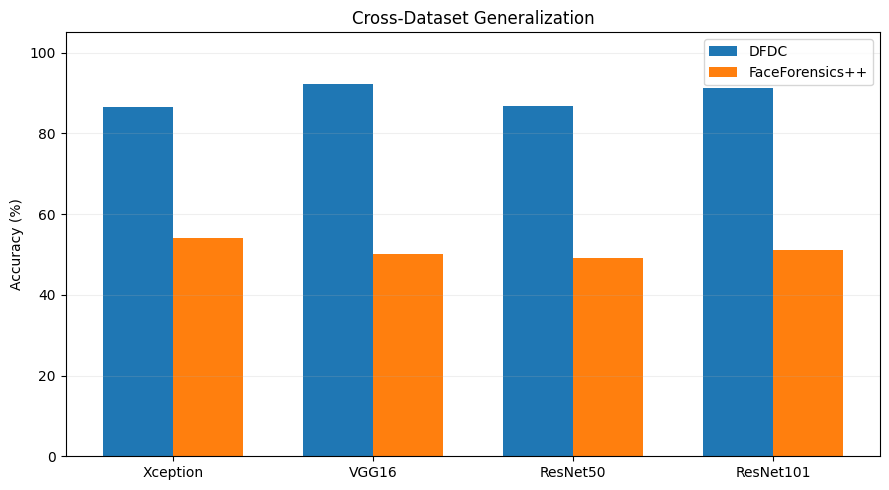

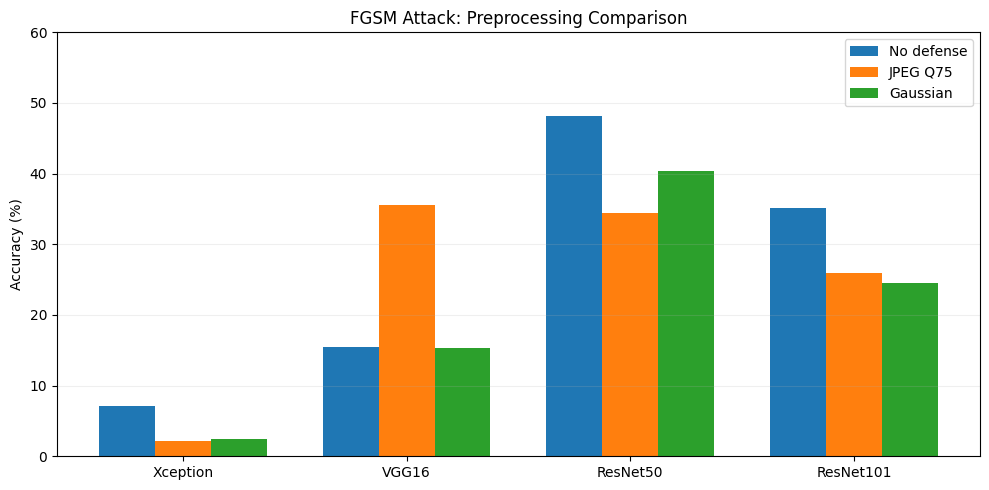

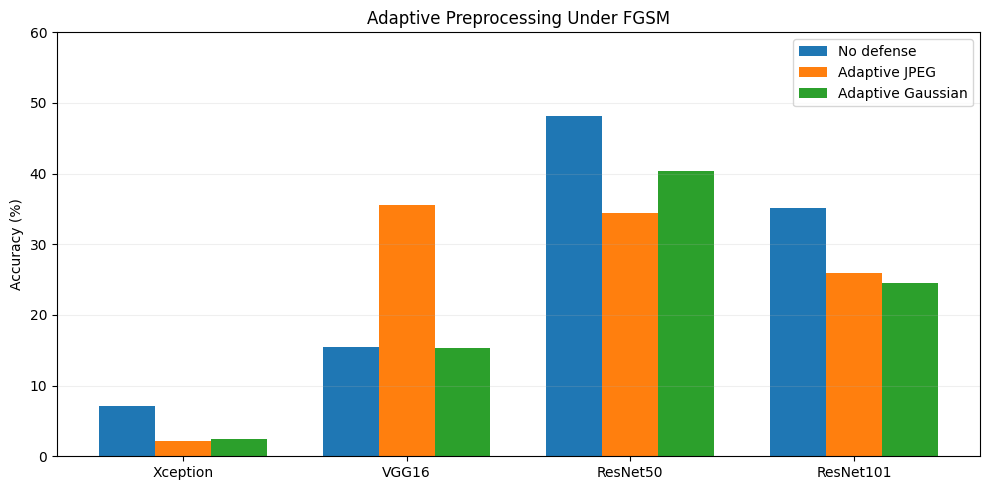

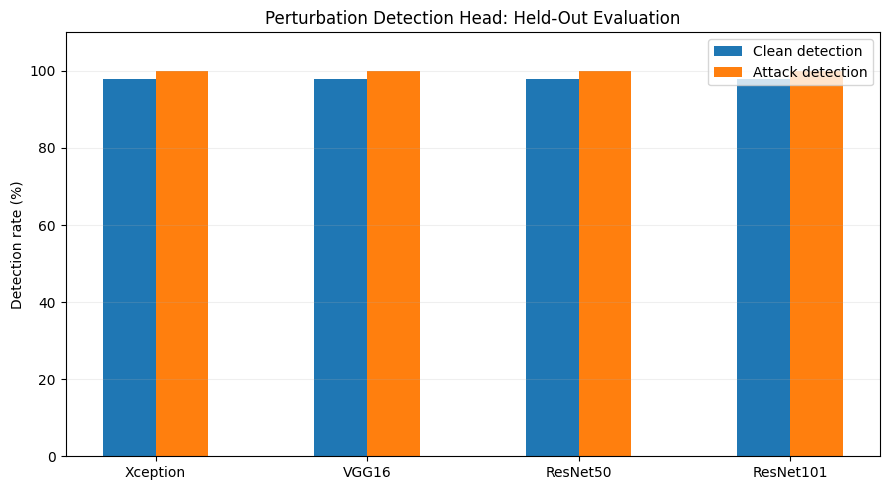

All four figures saved to: /kaggle/working/assignment3/final_figures


In [12]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUT = Path("/kaggle/working/assignment3")
FIG = OUT / "final_figures"
FIG.mkdir(parents=True, exist_ok=True)

clean = pd.read_csv(OUT / "ffpp_clean_results.csv")
fgsm = pd.read_csv(OUT / "ffpp_fgsm_results.csv")
jpeg = pd.read_csv(OUT / "ffpp_jpeg_defense_results.csv")
gauss = pd.read_csv(OUT / "ffpp_gaussian_results.csv")
adaptive = pd.read_csv(OUT / "adaptive_pipeline_results.csv")
head = pd.read_csv(OUT / "head_test_results.csv")

models = ["xception", "vgg16", "resnet50", "resnet101"]
names = ["Xception", "VGG16", "ResNet50", "ResNet101"]

def ordered(series):
    return series.reindex(models).to_numpy() * 100

# FIGURE 1: Cross-dataset generalization
dfdc_accuracy = pd.Series({
    "xception": 0.8648,
    "vgg16": 0.9230,
    "resnet50": 0.8686,
    "resnet101": 0.9130
})

ffpp_accuracy = clean.set_index("model")["accuracy"]

x = np.arange(len(models))
w = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - w/2, ordered(dfdc_accuracy), w, label="DFDC")
ax.bar(x + w/2, ordered(ffpp_accuracy), w, label="FaceForensics++")
ax.set_xticks(x, names)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Cross-Dataset Generalization")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIG / "01_cross_dataset_accuracy.png", dpi=300)
plt.show()
plt.close(fig)

# FIGURE 2: FGSM vs preprocessing
baseline = fgsm.set_index("model")["fgsm_accuracy"]

jpeg_fgsm = jpeg[
    jpeg["condition"] == "jpeg_fgsm"
].set_index("model")["accuracy"]

gauss_fgsm = gauss[
    gauss["condition"] == "gaussian_fgsm"
].set_index("model")["accuracy"]

fig, ax = plt.subplots(figsize=(10, 5))
w = 0.25
ax.bar(x - w, ordered(baseline), w, label="No defense")
ax.bar(x, ordered(jpeg_fgsm), w, label="JPEG Q75")
ax.bar(x + w, ordered(gauss_fgsm), w, label="Gaussian")
ax.set_xticks(x, names)
ax.set_ylabel("Accuracy (%)")
ax.set_title("FGSM Attack: Preprocessing Comparison")
ax.set_ylim(0, 60)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIG / "02_fgsm_defense_comparison.png", dpi=300)
plt.show()
plt.close(fig)

# FIGURE 3: Adaptive preprocessing
attacked = adaptive[adaptive["condition"] == "fgsm"]

adaptive_jpeg = attacked[
    attacked["defense"] == "jpeg"
].set_index("model")["adaptive_accuracy"]

adaptive_gauss = attacked[
    attacked["defense"] == "gaussian"
].set_index("model")["adaptive_accuracy"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w, ordered(baseline), w, label="No defense")
ax.bar(x, ordered(adaptive_jpeg), w, label="Adaptive JPEG")
ax.bar(x + w, ordered(adaptive_gauss), w, label="Adaptive Gaussian")
ax.set_xticks(x, names)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Adaptive Preprocessing Under FGSM")
ax.set_ylim(0, 60)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIG / "03_adaptive_comparison.png", dpi=300)
plt.show()
plt.close(fig)

# FIGURE 4: Detection-head performance
head = head.set_index("source_model")

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    x - w/2,
    ordered(head["clean_detection_rate"]),
    w,
    label="Clean detection"
)
ax.bar(
    x + w/2,
    ordered(head["attack_detection_rate"]),
    w,
    label="Attack detection"
)
ax.set_xticks(x, names)
ax.set_ylabel("Detection rate (%)")
ax.set_title("Perturbation Detection Head: Held-Out Evaluation")
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIG / "04_head_detection.png", dpi=300)
plt.show()
plt.close(fig)

print("All four figures saved to:", FIG)


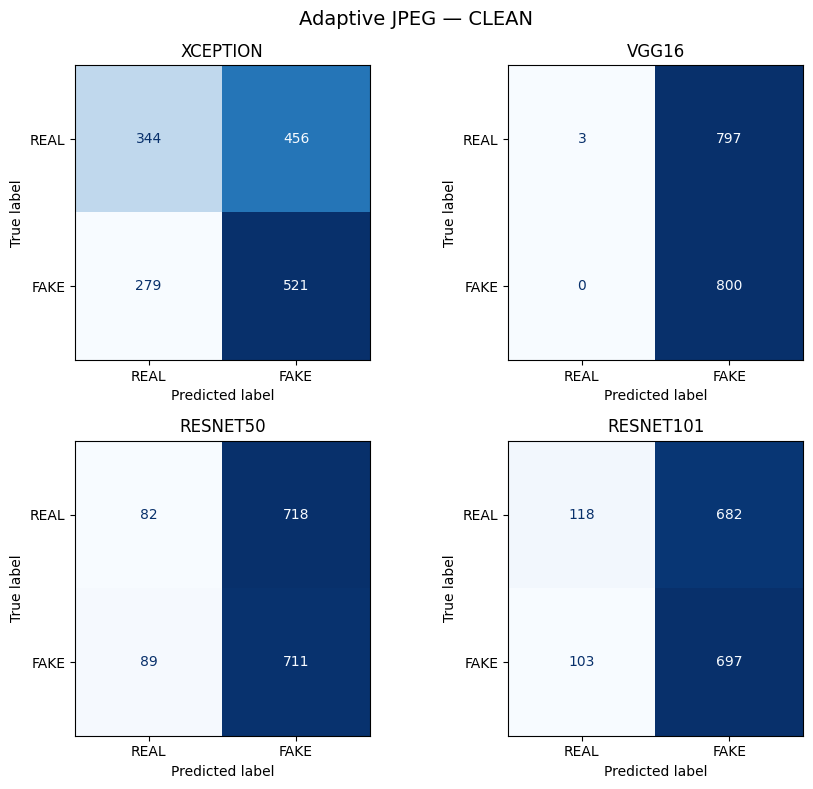

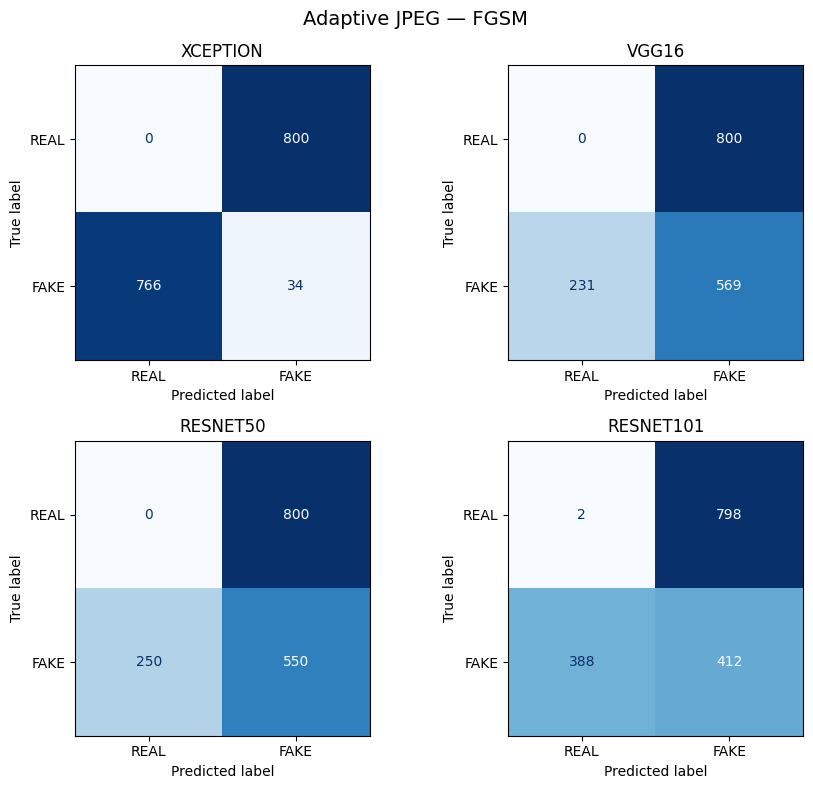

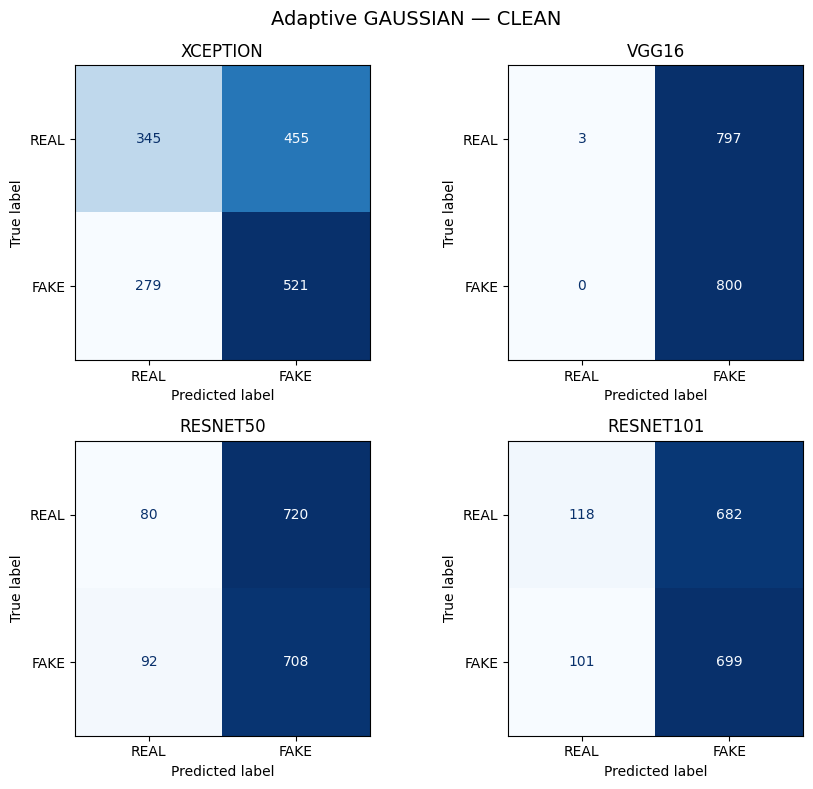

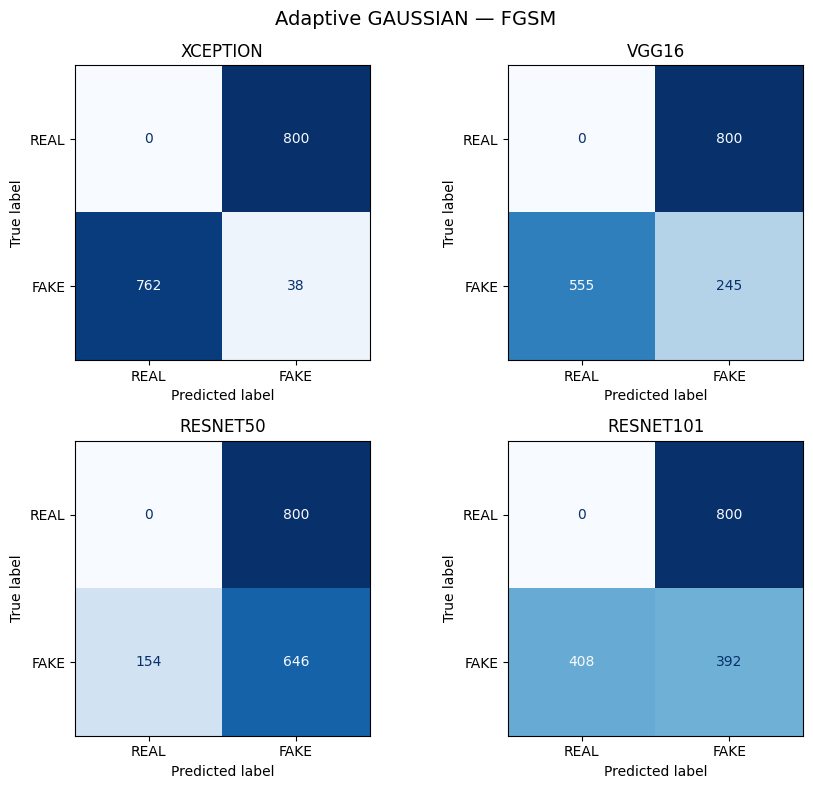


All confusion matrices saved!

Generated figures:
01_cross_dataset_accuracy.png
02_fgsm_defense_comparison.png
03_adaptive_comparison.png
04_head_detection.png
05_cm_gaussian_clean.png
05_cm_gaussian_fgsm.png
05_cm_jpeg_clean.png
05_cm_jpeg_fgsm.png


In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

OUT = Path("/kaggle/working/assignment3")
FIG = OUT / "final_figures"

preds = pd.read_csv(
    OUT / "adaptive_pipeline_predictions.csv"
)

models = ["xception", "vgg16", "resnet50", "resnet101"]
defenses = ["jpeg", "gaussian"]
conditions = ["clean", "fgsm"]

# Validate saved predictions
required = {
    "model", "defense", "condition",
    "label", "adaptive_pred"
}
assert required.issubset(preds.columns)

for defense in defenses:
    for condition in conditions:

        fig, axes = plt.subplots(
            2, 2, figsize=(9, 8)
        )

        for ax, model in zip(axes.flat, models):

            part = preds[
                (preds["model"] == model) &
                (preds["defense"] == defense) &
                (preds["condition"] == condition)
            ]

            assert len(part) == 1600, (
                f"Unexpected sample count: "
                f"{model}, {defense}, {condition}"
            )

            cm = confusion_matrix(
                part["label"],
                part["adaptive_pred"],
                labels=[0, 1]
            )

            ConfusionMatrixDisplay(
                cm, display_labels=["REAL", "FAKE"]
            ).plot(
                ax=ax,
                cmap="Blues",
                colorbar=False,
                values_format="d"
            )

            ax.set_title(model.upper())

        fig.suptitle(
            f"Adaptive {defense.upper()} — {condition.upper()}",
            fontsize=14
        )
        fig.tight_layout()

        filename = (
            f"05_cm_{defense}_{condition}.png"
        )

        fig.savefig(
            FIG / filename,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

print("\nAll confusion matrices saved!")
print("\nGenerated figures:")

for f in sorted(FIG.glob("*.png")):
    print(f.name)


In [14]:

from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path("/kaggle/working/assignment3")
OUT.mkdir(parents=True, exist_ok=True)

preds = pd.read_csv(
    OUT / "adaptive_pipeline_predictions.csv"
)

manifest = pd.read_csv(
    OUT / "ffpp_evaluation_manifest.csv"
)

# Validate source files
assert manifest["path"].is_unique
assert len(manifest) == 1600
assert {0, 1} == set(manifest["label"])

# Add original video information for cluster bootstrap
metadata = manifest[
    ["path", "label", "method", "video_id"]
].copy()

# Safely merge if needed
preds = preds.drop(
    columns=["method", "video_id"],
    errors="ignore"
)

preds = preds.merge(
    metadata,
    on=["path", "label"],
    how="left",
    validate="many_to_one"
)

assert preds["video_id"].notna().all()

# A fake video name can occur in multiple methods.
preds["cluster_id"] = (
    preds["method"].astype(str)
    + "/"
    + preds["video_id"].astype(str)
)

MODELS = [
    "xception", "vgg16",
    "resnet50", "resnet101"
]

DEFENSES = ["jpeg", "gaussian"]
CONDITIONS = ["clean", "fgsm"]

N_BOOT = 2000
SEED = 42

def cluster_bootstrap(part, n_boot=2000, seed=42):
    """
    Paired, class-stratified video-cluster bootstrap.

    Returns confidence intervals for:
    - baseline accuracy
    - adaptive accuracy
    - adaptive minus baseline (percentage points)

    Resampling is within REAL and FAKE video clusters,
    preserving each sampled video's frames.
    """

    rng = np.random.default_rng(seed)

    y = part["label"].to_numpy(dtype=int)
    base = part["original_pred"].to_numpy(dtype=int)
    adaptive = part["adaptive_pred"].to_numpy(dtype=int)

    base_correct = (base == y).astype(float)
    adaptive_correct = (adaptive == y).astype(float)

    # Aggregate frame-level correctness within video clusters.
    stats = part[
        ["cluster_id", "label"]
    ].copy()

    stats["base_correct"] = base_correct
    stats["adaptive_correct"] = adaptive_correct
    stats["n"] = 1

    grouped = stats.groupby(
        ["label", "cluster_id"], as_index=False
    ).agg({
        "base_correct": "sum",
        "adaptive_correct": "sum",
        "n": "sum"
    })

    arrays = []
    for label in [0, 1]:
        g = grouped[grouped["label"] == label]
        assert len(g) > 0
        arrays.append(
            g[["base_correct", "adaptive_correct", "n"]]
            .to_numpy(dtype=float)
        )

    baseline_samples = np.zeros(n_boot)
    adaptive_samples = np.zeros(n_boot)

    for b in range(n_boot):
        sums = np.zeros(3, dtype=float)

        for a in arrays:
            indices = rng.integers(
                0, len(a), size=len(a)
            )
            sums += a[indices].sum(axis=0)

        baseline_samples[b] = sums[0] / sums[2]
        adaptive_samples[b] = sums[1] / sums[2]

    delta_samples = (
        adaptive_samples - baseline_samples
    ) * 100

    def ci(x):
        return np.percentile(x, [2.5, 97.5])

    return {
        "baseline_accuracy": base_correct.mean(),
        "adaptive_accuracy": adaptive_correct.mean(),
        "change_pp": (
            adaptive_correct.mean()
            - base_correct.mean()
        ) * 100,
        "baseline_ci_low": ci(baseline_samples)[0],
        "baseline_ci_high": ci(baseline_samples)[1],
        "adaptive_ci_low": ci(adaptive_samples)[0],
        "adaptive_ci_high": ci(adaptive_samples)[1],
        "change_ci_low_pp": ci(delta_samples)[0],
        "change_ci_high_pp": ci(delta_samples)[1],
        "n_video_clusters": grouped.shape[0],
        "n_images": len(part)
    }


results = []

for model in MODELS:
    for defense in DEFENSES:
        for condition in CONDITIONS:

            part = preds[
                (preds["model"] == model) &
                (preds["defense"] == defense) &
                (preds["condition"] == condition)
            ].copy()

            assert len(part) == 1600
            assert part["path"].is_unique
            assert part["original_pred"].notna().all()
            assert part["adaptive_pred"].notna().all()

            metrics = cluster_bootstrap(
                part, n_boot=N_BOOT, seed=SEED
            )

            results.append({
                "model": model,
                "defense": defense,
                "condition": condition,
                **metrics
            })

statistics = pd.DataFrame(results)

statistics.to_csv(
    OUT / "adaptive_statistical_analysis.csv",
    index=False
)

# Report-ready percentages
report = statistics.copy()

for col in [
    "baseline_accuracy",
    "adaptive_accuracy",
    "baseline_ci_low",
    "baseline_ci_high",
    "adaptive_ci_low",
    "adaptive_ci_high"
]:
    report[col] *= 100

report["adaptive_95CI"] = (
    report["adaptive_ci_low"].map("{:.2f}".format)
    + " – "
    + report["adaptive_ci_high"].map("{:.2f}".format)
)

report["change_95CI_pp"] = (
    report["change_ci_low_pp"].map("{:+.2f}".format)
    + " to "
    + report["change_ci_high_pp"].map("{:+.2f}".format)
)

cols = [
    "model", "defense", "condition",
    "baseline_accuracy", "adaptive_accuracy",
    "change_pp", "adaptive_95CI",
    "change_95CI_pp", "n_video_clusters"
]

print("=== FINAL STATISTICAL RESULTS ===")

display(
    report[cols].round(2)
)

report.to_csv(
    OUT / "report_ready_statistical_results.csv",
    index=False
)

print("\nFiles saved:")
print("adaptive_statistical_analysis.csv")
print("report_ready_statistical_results.csv")


=== FINAL STATISTICAL RESULTS ===


,model,defense,condition,baseline_accuracy,adaptive_accuracy,change_pp,adaptive_95CI,change_95CI_pp,n_video_clusters
0,xception,jpeg,clean,54.06,54.06,0.00,48.94 – 59.00,+0.00 to +0.00,200
1,xception,jpeg,fgsm,7.12,2.12,-5.00,0.88 – 3.56,-6.81 to -3.50,200
2,xception,gaussian,clean,54.06,54.12,0.06,49.12 – 59.06,+0.00 to +0.19,200
3,xception,gaussian,fgsm,7.12,2.38,-4.75,1.19 – 3.81,-6.12 to -3.50,200
4,vgg16,jpeg,clean,50.19,50.19,0.00,50.00 – 50.56,+0.00 to +0.00,200
5,vgg16,jpeg,fgsm,15.44,35.56,20.12,32.37 – 38.88,+17.19 to +22.94,200
6,vgg16,gaussian,clean,50.19,50.19,0.00,50.00 – 50.56,+0.00 to +0.00,200
7,vgg16,gaussian,fgsm,15.44,15.31,-0.13,12.00 – 18.62,-1.13 to +0.81,200
8,resnet50,jpeg,clean,49.19,49.56,0.37,46.69 – 52.50,-0.13 to +1.19,200
9,resnet50,jpeg,fgsm,48.12,34.38,-13.75,31.37 – 37.44,-16.56 to -11.19,200



Files saved:
adaptive_statistical_analysis.csv
report_ready_statistical_results.csv
